# ВКР: многоклассовая классификация объектов основных средств

Выпускная квалификационная работа (бакалавриат, 2026). Реестр основных средств инфраструктурных компаний: ~12,6 тыс. объектов, 383 наименования. Данные конфиденциальны и обезличены, исходный датасет не публикуется.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelBinarizer, PowerTransformer, OrdinalEncoder
from sklearn.cluster import DBSCAN
from sklearn.metrics import (silhouette_score, 
                             classification_report, 
                             confusion_matrix, 
                             f1_score, 
                             precision_score, 
                             recall_score, 
                             accuracy_score,
                             roc_auc_score)
import gower
import hdbscan
from sklearn.decomposition import PCA
import plotly.express as px
import plotly.graph_objects as go
from sklearn.manifold import TSNE
from fedot.api.main import Fedot
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_predict, StratifiedKFold, ParameterGrid
from imblearn.over_sampling import SMOTENC, RandomOverSampler, SMOTE, ADASYN
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, IsolationForest
from catboost import CatBoostClassifier
from collections import Counter
from tqdm import tqdm
from imblearn.under_sampling import RandomUnderSampler
import networkx as nx
from imblearn.pipeline import Pipeline as ImbPipeline
from category_encoders import TargetEncoder
from sklearn.preprocessing import LabelEncoder
import time
from ctgan import CTGAN
from sklearn.base import BaseEstimator
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from itertools import product
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from aeon.classification.sklearn import RotationForestClassifier

In [2]:
# исходный датасет конфиденциален и в репозиторий не включён
df = pd.read_excel('data/data.xlsx', sheet_name='данные')
df.head()

# Предобработка

In [3]:
df.columns = df.columns.str.strip()

Думаю стоит начать с засекречивания конфиденциальной информации, о чем меня и просили руководители. Среди преобразований в эксель можно выделить - создание признака "Лет в эксплуатации", так как с этой информацией легче работать в дальнейшем. Также стоимость основных средств была умножена на коэффициент, что не поменяет само распределение этого признака. Уже в самом пайтоне я решил создать признак "Федеральный округ", чтобы укрупнить признак "Регион", пока не уверен, что он мне понадобится для моделирования, но сейчас и не могу это проверить. Признаки "Федеральный округ", "Регион" и "Эксплуатирующая организация" были обезличены. Это существенно сужает именно экономический анализ, но без этого данные мне бы никто не предоставил.

> **Обезличивание.** Регионы сгруппированы в федеральные округа, после чего регионы, округа и эксплуатирующие организации заменены условными кодами (`Регион_N`, `Округ_N`, `Организация_N`). Код обезличивания и справочники соответствия не публикуются.


In [8]:
df.head()

,Эксплуатирующая организация,Регион,Лет в эксплуатации,Стоимость без НДС в ценах 2024 г.,Основное свойство,ед. изм.,Значение,Наименование,Федеральный округ
0,Организация_14,Регион_35,1,8.625357e+08,количество точек подключения,шт,1.0,Система управления технологическими процессами...,Округ_1
1,Организация_14,Регион_35,1,4.181210e+08,количество точек подключения,шт,NaN,Система управления технологическими процессами...,Округ_1
2,Организация_14,Регион_2,1,3.693608e+08,количество точек подключения,шт,NaN,Система управления технологическими процессами...,Округ_1
3,Организация_14,Регион_35,1,4.423769e+07,количество контролируемых параметров,шт,NaN,Система управления энергоснабжением автоматизи...,Округ_1
4,Организация_14,Регион_35,1,9.558990e+07,количество точек мониторинга,шт,NaN,"Система пожарной сигнализации, контроля загазо...",Округ_1


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12659 entries, 0 to 12658
Data columns (total 9 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Эксплуатирующая организация        12659 non-null  object 
 1   Регион                             12659 non-null  object 
 2   Лет в эксплуатации                 12659 non-null  int64  
 3   Стоимость без НДС в ценах 2024 г.  12659 non-null  float64
 4   Основное свойство                  12659 non-null  object 
 5   ед. изм.                           12659 non-null  object 
 6   Значение                           11030 non-null  float64
 7   Наименование                       12659 non-null  object 
 8   Федеральный округ                  12659 non-null  object 
dtypes: float64(2), int64(1), object(6)
memory usage: 890.2+ KB


Видно, что датасет имеет 12659 наблюдений и 9 столбцов. Типы данных корректны. На этом этапе заметно, что пропуски есть в столбце "Значение". Далее придется решить, что сделать с ними.

Хоть типы данных и не нарушены, но сами категориальные признаки проверить не будет лишним. Признак "Наименование" я проверил в экселе, так как тут не отображается полный массив. 

In [10]:
cat_cols = df.select_dtypes(include=["object", "category", "string"]).columns

for col in cat_cols:
    
    series = df[col]
    
    try:
        uniques = series.unique()
    except TypeError:
        uniques = series.apply(
            lambda x: tuple(x) if isinstance(x, list) else x
        ).unique()
    
    print(f"\n{col} ({len(uniques)} уникальных): {uniques}")


Эксплуатирующая организация (18 уникальных): ['Организация_14' 'Организация_6' 'Организация_18' 'Организация_10'
 'Организация_16' 'Организация_7' 'Организация_8' 'Организация_15'
 'Организация_4' 'Организация_12' 'Организация_11' 'Организация_13'
 'Организация_3' 'Организация_5' 'Организация_1' 'Организация_9'
... (вывод сокращён: 298 строк) ...
 'Установка зарядная углекислотная' 'Здание КИПиА'
 'Линия связи радиорелейная'
 'Установка резервуара/емкости противопожарного запаса'
 'Плоскостное спортивное сооружение'
 'Установка резервуара/емкости накопителя воды' 'Блок-бокс очистки воды'
 'Здание административное прочее'
 'Установка резервуаров, емкостей, газгольдеров прочая'
 'Установка регенерации фильтров масла'
 'Башня водопроводная (водонапорная)' 'Поле фильтрации' 'Биотуалет'
 'Здание производственно-административное' 'Радиомачты, отдельно стоящие'
 'Установка воздушного охлаждения охлаждающей жидкости' 'База рукавная'
 'Блок-бокс склада пенообразователя' 'Установка компрессорна

Как видно ниже, пропуски в столбце "Значение" составляют 12,87% от всего датасета. Считаю, что на данном этапе избыточно заполнять пропуски через модель, а в тупую заполнить их средним или даже медианой неправильно. Поэтому я решил заполнить пропуски через группировку по самым важным признакам, которые как раз и отображают структуру значений. В качестве таких признаков я выбрал - "Основное свойство", "Эксплуатирующую организацию", "Регион" и "Федеральный округ".

In [11]:
df.isna().sum()

Эксплуатирующая организация             0
Регион                                  0
Лет в эксплуатации                      0
Стоимость без НДС в ценах 2024 г.       0
Основное свойство                       0
ед. изм.                                0
Значение                             1629
Наименование                            0
Федеральный округ                       0
dtype: int64

In [12]:
round(df['Значение'].isna().sum() / df.shape[0] * 100, 2)

12.87

In [13]:
def fill_by_group_median(df):

    df = df.copy()

    df["Значение"] = df["Значение"].fillna(
        df.groupby(
            ["Основное свойство", "Эксплуатирующая организация", "Регион", "Федеральный округ"]
        )["Значение"].transform("median")
    )

    df["Значение"] = df["Значение"].fillna(
        df.groupby(
            ["Основное свойство", "Эксплуатирующая организация", "Регион"]
        )["Значение"].transform("median")
    )
    
    df["Значение"] = df["Значение"].fillna(
        df.groupby(
            ["Основное свойство", "Эксплуатирующая организация"]
        )["Значение"].transform("median")
    )

    df["Значение"] = df["Значение"].fillna(
        df.groupby(
            ["Основное свойство"]
        )["Значение"].transform("median")
    )

    return df

После заполнения через группировку остался только 51 пропуск, что составляет 0,4% от датасета. Их я уже не могу заполнить, так как это как раз те основные свойства, которые не получилось заполнить в течение проекта. Само заполнение происходило через описание характеристик основного средства. К сожалению, бухгалтеры, которые заполняют эти характеристики, не знают, какая информация в дальнейшем точно понадобится остальным подразделениям. Этот 51 пропуск я смело удалил.

In [14]:
df = fill_by_group_median(df)

In [15]:
df.isna().sum()

Эксплуатирующая организация           0
Регион                                0
Лет в эксплуатации                    0
Стоимость без НДС в ценах 2024 г.     0
Основное свойство                     0
ед. изм.                              0
Значение                             51
Наименование                          0
Федеральный округ                     0
dtype: int64

In [16]:
round(df['Значение'].isna().sum() / df.shape[0] * 100, 2)

0.4

In [17]:
df[df['Значение'].isna()]

,Эксплуатирующая организация,Регион,Лет в эксплуатации,Стоимость без НДС в ценах 2024 г.,Основное свойство,ед. изм.,Значение,Наименование,Федеральный округ
2894,Организация_14,Регион_35,4,8.715102e+06,расчетное количество огнетушащего вещества,кг,NaN,Установка пожаротушения газового,Округ_1
2895,Организация_14,Регион_35,4,6.947068e+06,расчетное количество огнетушащего вещества,кг,NaN,Установка пожаротушения газового,Округ_1
2896,Организация_14,Регион_2,4,6.896347e+06,расчетное количество огнетушащего вещества,кг,NaN,Установка пожаротушения газового,Округ_1
3048,Организация_18,Регион_49,4,3.738133e+05,количество радиоканалов,шт,NaN,Сети связи и радиофикации,Округ_7
3050,Организация_18,Регион_49,4,6.297894e+05,расчетное количество огнетушащего вещества,кг,NaN,Установка пожаротушения газового,Округ_7
3219,Организация_16,Регион_5,5,4.185682e+07,расчетное количество огнетушащего вещества,кг,NaN,Установка пожаротушения газового,Округ_9
3724,Организация_10,Регион_21,7,2.566848e+06,расчетное количество огнетушащего вещества,кг,NaN,Установка пожаротушения газового,Округ_4
4339,Организация_6,Регион_37,9,1.035320e+08,расчетное количество огнетушащего вещества,кг,NaN,Установка пожаротушения газового,Округ_9
5016,Организация_16,Регион_33,9,3.006007e+05,количество защищаемых помещений,шт,NaN,Система контроля и управления доступом,Округ_4
5017,Организация_6,Регион_37,9,3.257691e+07,количество защищаемых помещений,шт,NaN,Система контроля и управления доступом,Округ_9


In [18]:
df = df.dropna()

In [19]:
df.isna().sum()

Эксплуатирующая организация          0
Регион                               0
Лет в эксплуатации                   0
Стоимость без НДС в ценах 2024 г.    0
Основное свойство                    0
ед. изм.                             0
Значение                             0
Наименование                         0
Федеральный округ                    0
dtype: int64

На первый взгляд может показаться, что в датасете целый 461 дубликат, но на самом деле это не так. Каждое основное средство имеет свой инвентарный номер, которые мне пришлось удалить из-за конфиденциальности.  Сами инвентарные номера я проверил, среди них дубликатов не было обнаружено.

In [20]:
df.duplicated().sum()

461

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12608 entries, 0 to 12658
Data columns (total 9 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Эксплуатирующая организация        12608 non-null  object 
 1   Регион                             12608 non-null  object 
 2   Лет в эксплуатации                 12608 non-null  int64  
 3   Стоимость без НДС в ценах 2024 г.  12608 non-null  float64
 4   Основное свойство                  12608 non-null  object 
 5   ед. изм.                           12608 non-null  object 
 6   Значение                           12608 non-null  float64
 7   Наименование                       12608 non-null  object 
 8   Федеральный округ                  12608 non-null  object 
dtypes: float64(2), int64(1), object(6)
memory usage: 985.0+ KB


Данные очищены и готовы к анализу.

# Исследовательский анализ данных

Первое, что меня заинтересовало, это география в данных. Жаль, что данные закодированы и нельзя привнести экономический смысл в этот анализ. Сперва мне хотелось вывести топы по доле наблюдений по Федеральным округам, Регионам и Эксплуатирующим организациям. Также последние два признака я группировал по Федеральным округам для укрупнения.

In [22]:
fo_counts = df['Федеральный округ'].value_counts().reset_index()
fo_counts.columns = ['Федеральный округ', 'Количество']

total = len(df)
fo_counts['Процент'] = (fo_counts['Количество'] / total * 100).round(2)

fo_counts

,Федеральный округ,Количество,Процент
0,Округ_4,4188,33.22
1,Округ_9,1998,15.85
2,Округ_1,1970,15.62
3,Округ_7,1497,11.87
4,Округ_8,933,7.40
5,Округ_3,854,6.77
6,Округ_6,563,4.47
7,Округ_5,304,2.41
8,Округ_2,301,2.39


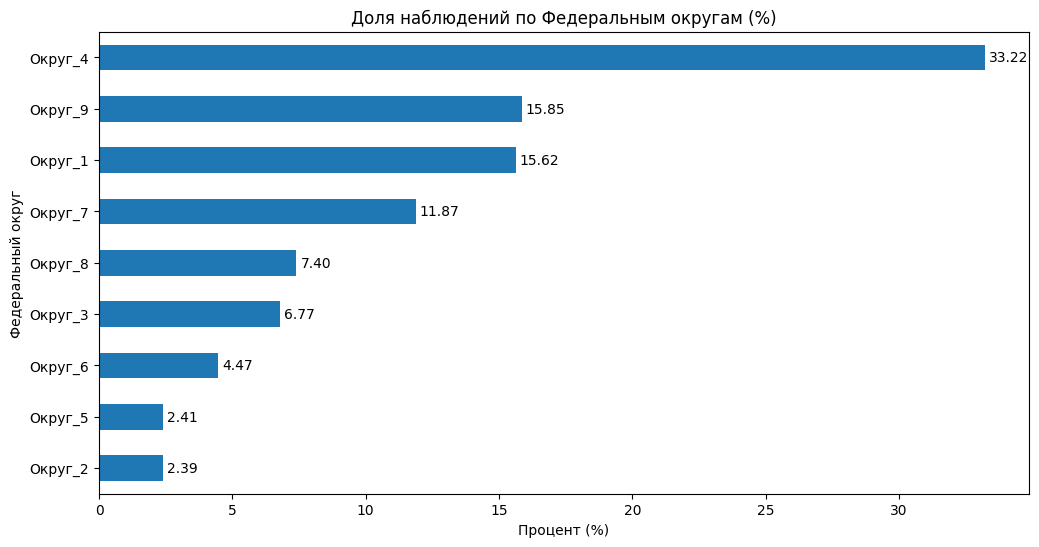

In [23]:
plt.figure(figsize=(12,6))

ax = (
    df['Федеральный округ']
    .value_counts(normalize=True)   
    .mul(100)                       
    .sort_values(ascending=True)
    .plot(kind='barh', title='Доля наблюдений по Федеральным округам (%)')
)

ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)

plt.xlabel("Процент (%)")
plt.show()

Видно, что абсолютный лидер - Округ 4, он занимает треть всего датасета (33,22%). Например, второе и третье место в сумме не дают такую долю, про остальные округи можно промолчать. Вероятно, Округ 4 — ключевой производственный кластер. После него следуют Округи в следующем порядке - 9 (15,85%), 1 (15,62%), 7 (11,87%), 8 (7,40%), 3 (6,77%), 6 (4,47%), 5 (2,41%) и 2 (2,39%).

In [24]:
region_counts = df['Регион'].value_counts().reset_index()
region_counts.columns = ['Регион', 'Количество']

region_counts['Процент'] = (region_counts['Количество'] / total * 100).round(2)

region_counts.head(10)

,Регион,Количество,Процент
0,Регион_33,2498,19.81
1,Регион_35,1209,9.59
2,Регион_49,1184,9.39
3,Регион_14,850,6.74
4,Регион_6,701,5.56
5,Регион_5,686,5.44
6,Регион_2,559,4.43
7,Регион_37,361,2.86
8,Регион_39,354,2.81
9,Регион_17,345,2.74


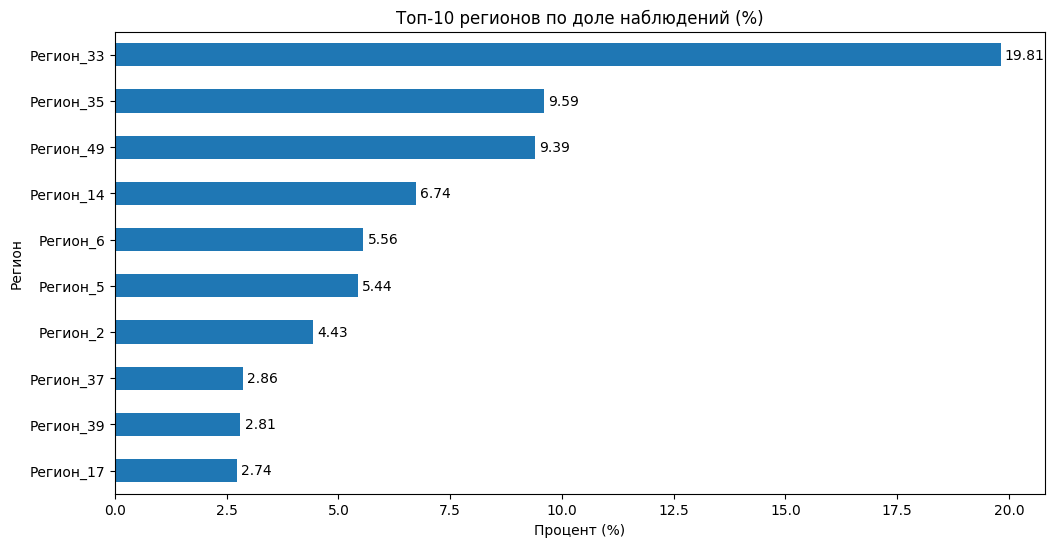

In [25]:
plt.figure(figsize=(12,6))

ax = (
    df['Регион']
    .value_counts(normalize=True)
    .mul(100)
    .sort_values(ascending=True)
    .tail(10)
    .plot(kind='barh', title='Топ-10 регионов по доле наблюдений (%)')
)

ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)

plt.xlabel("Процент (%)")
plt.show()

Похожая ситуация наблюдается и среди Регионов. Лидер среди Регионов - Регион 33 (19,81%). Только на этот раз второе и третье место в сумме хотя бы могут немного обогнать его. Разница между остальными Регионами по доле уже не такая большая. После Региона 33 идут 35 (9,59%), 49 (9,39%), 14 (6,74%), 6 (5,56%), 5 (5,44%), 2 (4,43%), 37 (2,86%), 39 (2,81%), 17 (2,74%).

In [26]:
counts = (
    df.groupby(["Федеральный округ", "Регион"])
      .size()
      .reset_index(name="Количество")
)

total = len(df)

counts["Процент"] = (counts["Количество"] / total) * 100
counts["Процент"] = counts["Процент"].round(2)

counts = counts.sort_values("Процент", ascending=False)
counts.head(10)

,Федеральный округ,Регион,Количество,Процент
19,Округ_4,Регион_33,2498,19.81
2,Округ_1,Регион_35,1209,9.59
32,Округ_7,Регион_49,1184,9.39
45,Округ_9,Регион_14,850,6.74
20,Округ_4,Регион_6,701,5.56
49,Округ_9,Регион_5,686,5.44
0,Округ_1,Регион_2,559,4.43
48,Округ_9,Регион_37,361,2.86
12,Округ_3,Регион_39,354,2.81
14,Округ_4,Регион_17,345,2.74


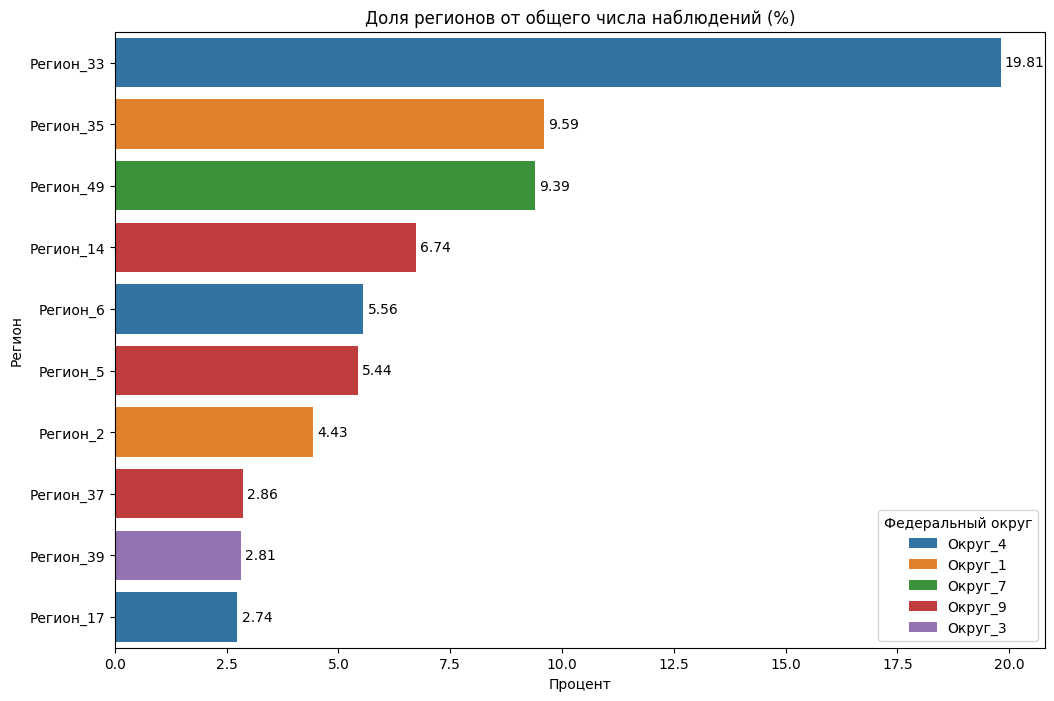

In [27]:
plt.figure(figsize=(12,8))

ax = sns.barplot(
    data=counts.head(10),
    x="Процент",
    y="Регион",
    hue="Федеральный округ",
    dodge=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Доля регионов от общего числа наблюдений (%)")
plt.show()

Теперь понятно, чем вызван такой отрыв Округа 4 от остальных (в него входит абсолютный топ 1 - Регион 33, также Регионы 6 и 17). Также в топе Регионы 35, 37 и 2 (Округ 1), 14 и 2 (Округ 1), Регион 49 (округ 7) и Регион 39 (Округ 3).

In [28]:
total = len(df)

org_counts = df['Эксплуатирующая организация'].value_counts().reset_index()
org_counts.columns = ['Эксплуатирующая организация', 'Количество']

org_counts['Процент'] = (org_counts['Количество'] / total * 100).round(2)

org_counts.head(10)

,Эксплуатирующая организация,Количество,Процент
0,Организация_16,4568,36.23
1,Организация_14,2533,20.09
2,Организация_6,1199,9.51
3,Организация_10,788,6.25
4,Организация_3,542,4.30
5,Организация_13,478,3.79
6,Организация_8,440,3.49
7,Организация_12,405,3.21
8,Организация_7,404,3.20
9,Организация_11,354,2.81


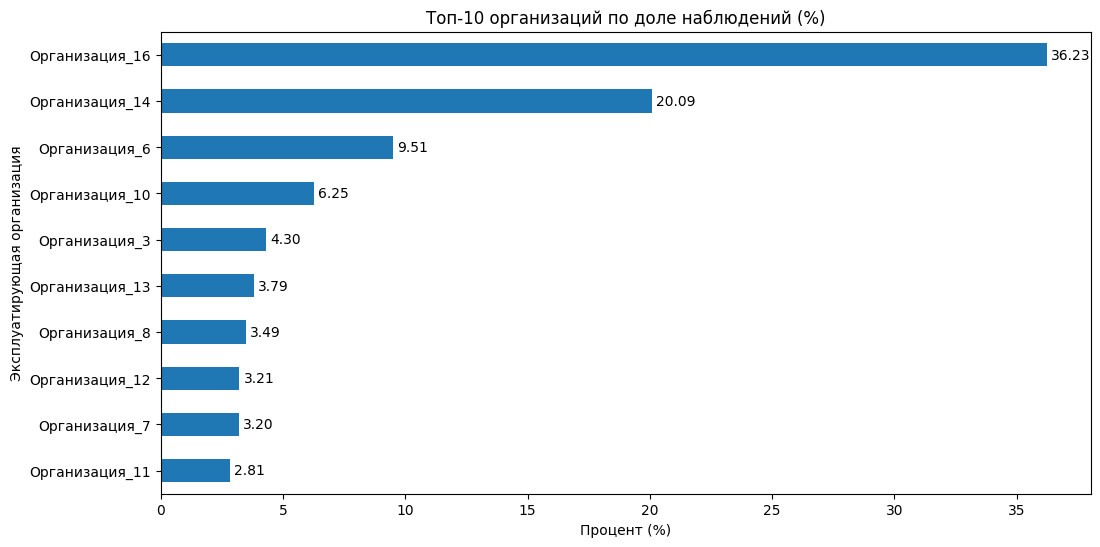

In [29]:
plt.figure(figsize=(12,6))

ax = (
    df['Эксплуатирующая организация']
    .value_counts(normalize=True)
    .mul(100)
    .sort_values(ascending=True)
    .tail(10)
    .plot(
        kind='barh',
        title='Топ-10 организаций по доле наблюдений (%)',
        legend=False
    )
)

ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)

plt.xlabel("Процент (%)")
plt.show()

По Организациям наблюдаем похожую картину, есть абсолютный лидер - Организация 16 (36,23%). Только теперь второе и третье место не идут вровень. Начиная с 4 места разница между организациями еще вовсе небольшая. После Организации 16 следуют 14 (20,09%), 6 (9,51%), 10 (6,25%), 3 (4,3%), 13 (3,79%), 8 (3,49%), 12 (3,21%), 7 (3,20%) и 11 (2,81%).

In [30]:
counts_org = (
    df.groupby(["Федеральный округ", "Эксплуатирующая организация"])
      .size()
      .reset_index(name="Количество")
)

total = len(df)
counts_org["Процент"] = (counts_org["Количество"] / total) * 100
counts_org["Процент"] = counts_org["Процент"].round(2)

counts_org = counts_org.sort_values("Процент", ascending=False)

counts_org.head(10)

,Федеральный округ,Эксплуатирующая организация,Количество,Процент
9,Округ_4,Организация_16,3483,27.63
0,Округ_1,Организация_14,1970,15.62
24,Округ_9,Организация_6,1199,9.51
8,Округ_4,Организация_10,705,5.59
14,Округ_7,Организация_16,668,5.30
11,Округ_6,Организация_14,563,4.47
23,Округ_9,Организация_3,542,4.30
13,Округ_7,Организация_13,478,3.79
19,Округ_8,Организация_7,404,3.20
2,Округ_3,Организация_11,354,2.81


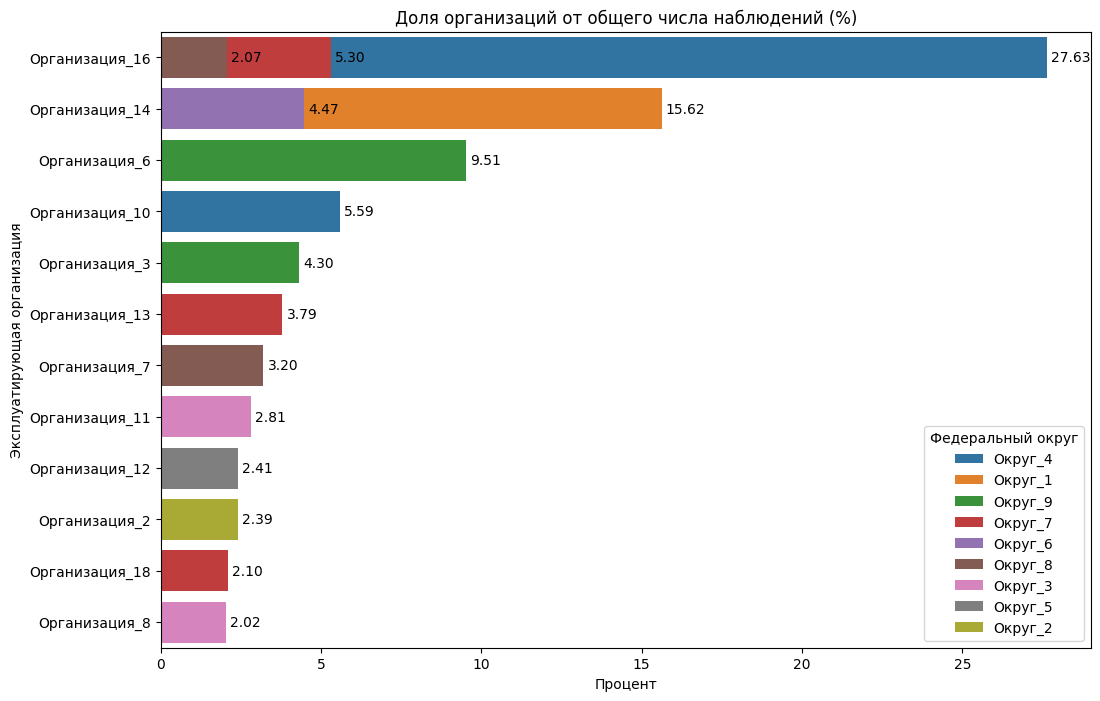

In [31]:
plt.figure(figsize=(12,8))

ax = sns.barplot(
    data=counts_org.head(15),
    x="Процент",
    y="Эксплуатирующая организация",
    hue="Федеральный округ",
    dodge=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

ax.set_title("Доля организаций от общего числа наблюдений (%)")
plt.show()

При укрупнении по Федеральным округам такая же картина. Абсолютный лидер Организация 16 задействована в Округе 4 и не только. Интересно, что первые 2 организации сосредоточены в нескольких округах. Лидеры среди округов входят Организации 16 и 10 (Округ 4), Организации 6 и 3 (Округ 9), Организация 14 (Округ 1), Организации 16, 13 и 18 (Округ 7), остальные более малочисленные для описания.

In [32]:
counts_name = (
    df.groupby("Наименование")
      .size()
      .reset_index(name="Количество")
)

total = len(df)
counts_name["Процент"] = (counts_name["Количество"] / total) * 100
counts_name["Процент"] = counts_name["Процент"].round(2)

top_name = counts_name.sort_values("Процент", ascending=False).head(15)
top_name

,Наименование,Количество,Процент
168,Площадка производственная,635,5.04
149,Мачта прожекторная с молниеотводом,612,4.85
178,Подъездная автодорога,494,3.92
295,Установка газотурбинных агрегатов,440,3.49
204,Сети канализации внутриплощадочные,401,3.18
142,Линия связи кабельная,350,2.78
138,Комплекс технических средств охраны,324,2.57
145,Линия электропередачи кабельная,317,2.51
144,Линия электропередачи воздушная,315,2.50
153,Объектовая охранная сигнализация,264,2.09


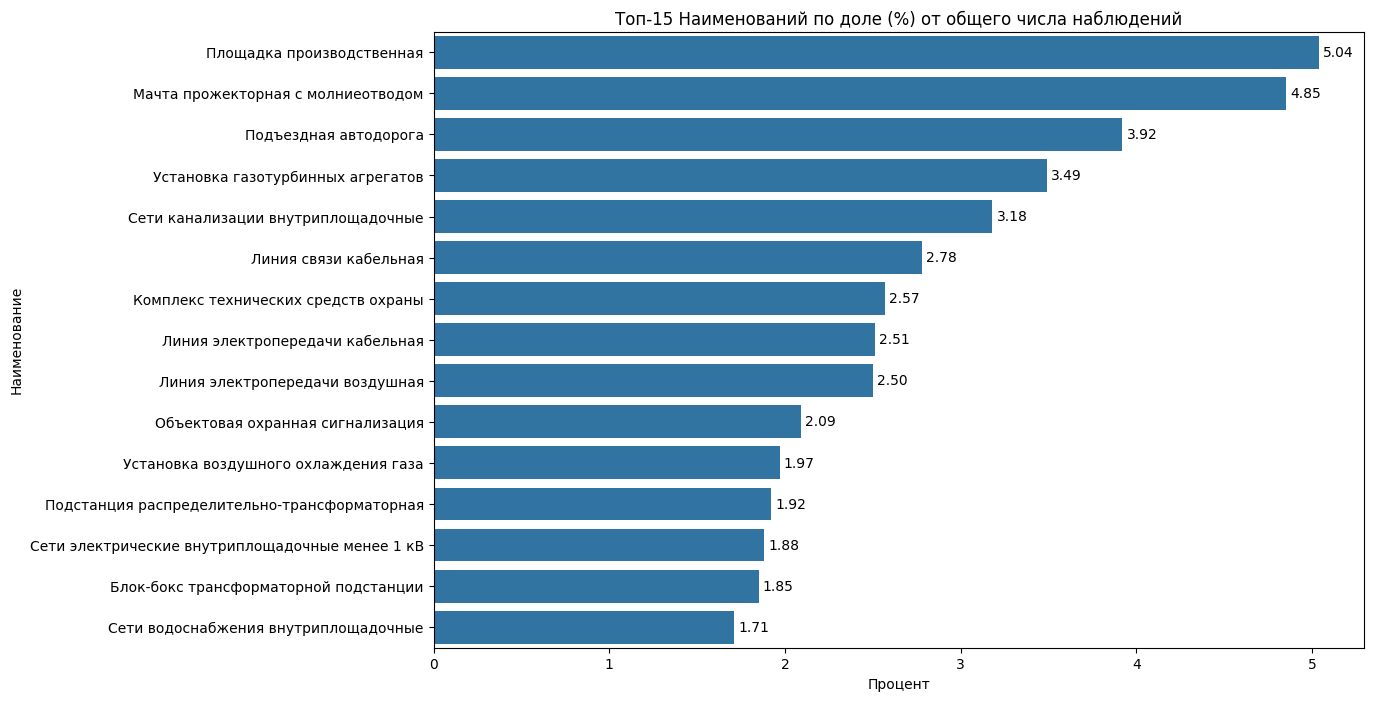

In [33]:
plt.figure(figsize=(12,8))

ax = sns.barplot(
    data=top_name.sort_values("Процент", ascending=False),
    x="Процент",
    y="Наименование",
    dodge=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

ax.set_title("Топ-15 Наименований по доле (%) от общего числа наблюдений")
plt.show()

Видно, что в ранжировании Наименований нет абсолютного лидера. Все идет ровно - Наименования от 4 до 5, от 3 до 4, от 2 до 3 и меньше двух.

In [34]:
down_name = counts_name.sort_values("Процент", ascending=False).tail(20)

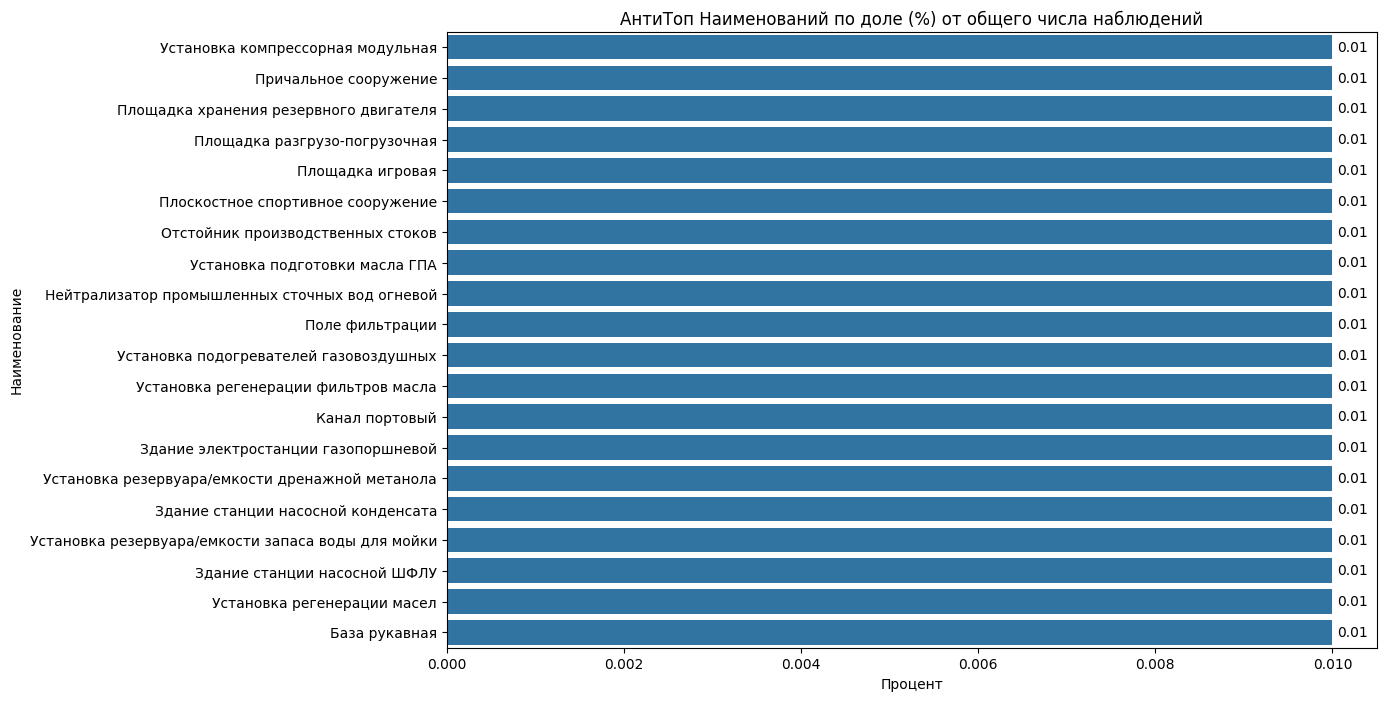

In [35]:
plt.figure(figsize=(12,8))

ax = sns.barplot(
    data=down_name.sort_values("Процент", ascending=False),
    x="Процент",
    y="Наименование",
    dodge=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

ax.set_title("АнтиТоп Наименований по доле (%) от общего числа наблюдений")
plt.show()

Больше меня смущает ситуация а антирейтингом. Последние 20 Наименований имеют меньше 0,01% (1 наблюдение). Это плохо скажется на дальнейшем моделировании. Такие случаи придется удалить, но тогда какой допустимый объем объектов?

In [36]:
counts_units = (
    df.groupby("ед. изм.")
      .size()
      .reset_index(name="Количество")
)

total = len(df)
counts_units["Процент"] = (counts_units["Количество"] / total) * 100
counts_units["Процент"] = counts_units["Процент"].round(2)

counts_units = counts_units.sort_values("Процент", ascending=False)

counts_units.head(10)

,ед. изм.,Количество,Процент
12,м,5357,42.49
13,м2,1887,14.97
21,шт,1414,11.22
16,м3/ч,1128,8.95
14,м3,846,6.71
8,кВ*А,705,5.59
6,МВт (1000 кВт),610,4.84
9,кВт,221,1.75
2,1000 м3/ч,168,1.33
7,кВ,65,0.52


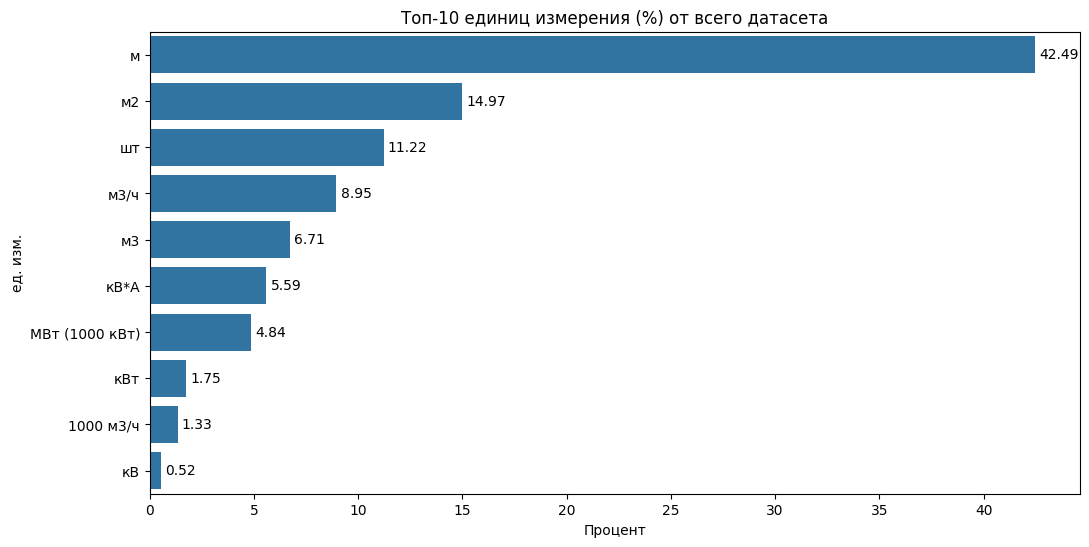

In [37]:
top15_units = counts_units.head(10).sort_values("Процент", ascending=False)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=top15_units,
    x="Процент",
    y="ед. изм."
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

ax.set_title("Топ-10 единиц измерения (%) от всего датасета")
plt.show()

Вот пока самая неприятная ситуация в датасете, потому что я планировал создавать классу внутри единиц измерений. А как бы уже даже 5% от датасета - это 632 наблюдения. Единица измерения "м" занимает больше, чем места 2-5 в сумме (42,49%). Но радует, что тут есть уже хоть какой-то анализ. Видно, что на балансе организаций много разных протяженных основных средств - различные трубы, ограждения и линии электропередач, но это сугубо моя гипотеза. Больше, чем в 2,5 раза (14,97%) меньше помещений и зданий. Еще меньше основных средств которые можно посчитать (11,22%), оценить производительность (8,95%), объем (6,71%) и прочее. 

In [38]:
counts_prop = (
    df.groupby(["Основное свойство", "ед. изм."])
      .size()
      .reset_index(name="Количество")
)

total = len(df)
counts_prop["Процент"] = (counts_prop["Количество"] / total) * 100
counts_prop["Процент"] = counts_prop["Процент"].round(2)

counts_prop = counts_prop.sort_values("Процент", ascending=False)

counts_prop.head(10)

,Основное свойство,ед. изм.,Количество,Процент
49,протяженность,м,3959,31.40
36,площадь общая,м2,1858,14.74
39,производительность (объемная),м3/ч,904,7.17
2,высота,м,872,6.92
30,объем,м3,655,5.20
26,мощность установки суммарная,МВт (1000 кВт),478,3.79
34,периметр защищаемых объектов,м,361,2.86
15,количество точек мониторинга,шт,354,2.81
16,количество точек подключения,шт,297,2.36
21,мощность подстанции,кВ*А,287,2.28


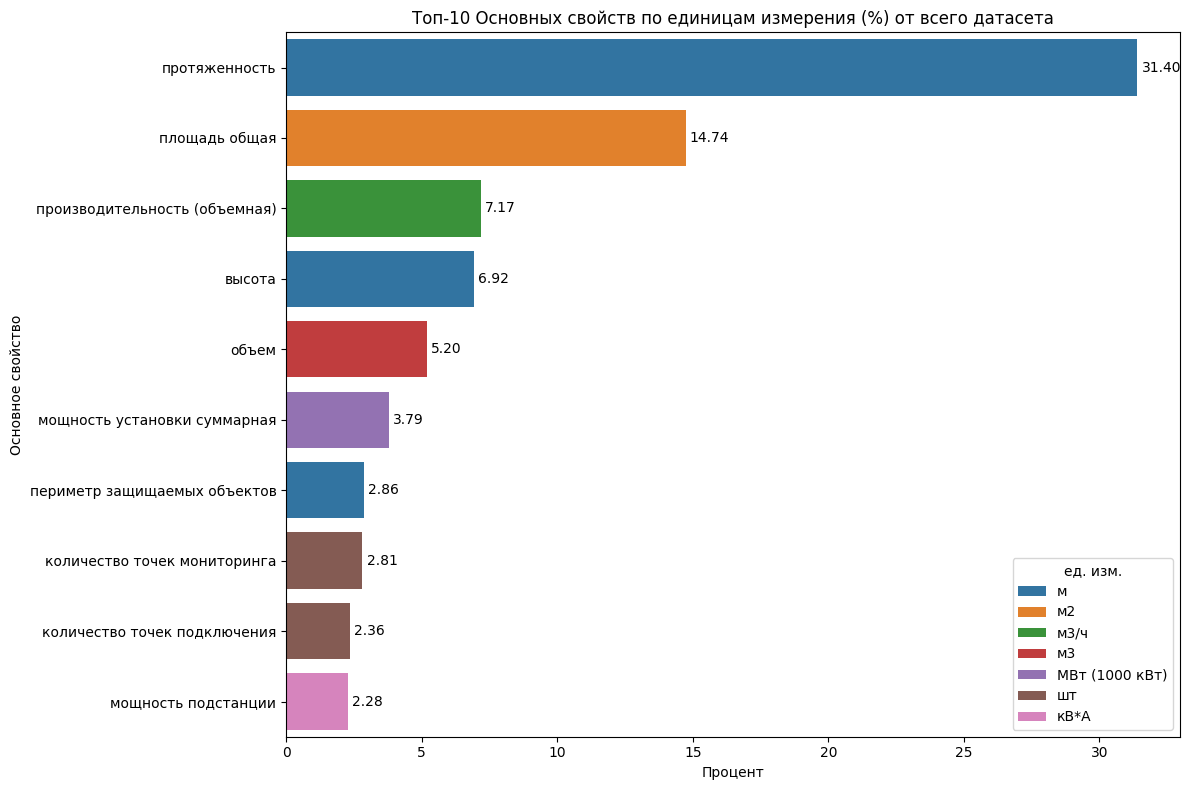

In [39]:
top_prop = counts_prop.head(10).sort_values("Процент", ascending=False)

plt.figure(figsize=(12,8))

ax = sns.barplot(
    data=top_prop,
    x="Процент",
    y="Основное свойство",
    hue="ед. изм."
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

ax.set_title("Топ-10 Основных свойств по единицам измерения (%) от всего датасета")
plt.tight_layout()
plt.show()

Как говорилось раньше, "м" отвечают за протяженность, высоту и периметр, "м2" - за площадь, "м3/ч" - за производительность, а вот за "шт" - множество мелких основных средств.

In [40]:
num_cols = df.select_dtypes(include=["int64", "float64"]).columns
cat_cols = df.select_dtypes(include=["object", "category", "string"]).columns

Выбросы хотелось только посмотреть, удалять я их ни в коем случае не буду, так как пропадет вся структура данных. Это совершенно нормально, что огромная компания имеет как и дешевую мышку, так и дорогой завод; как немощную установку, так и длинную трубу.

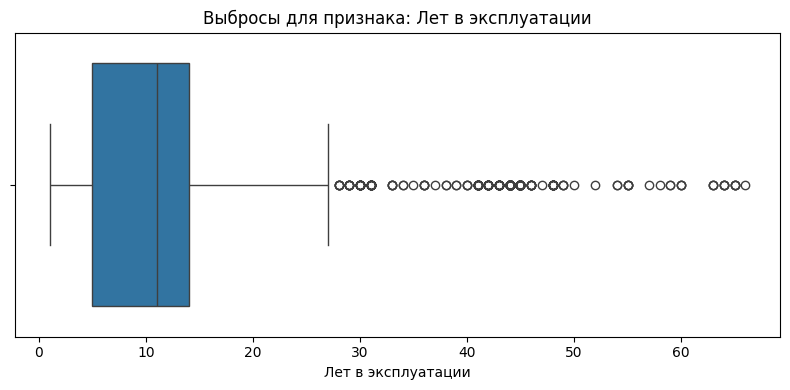

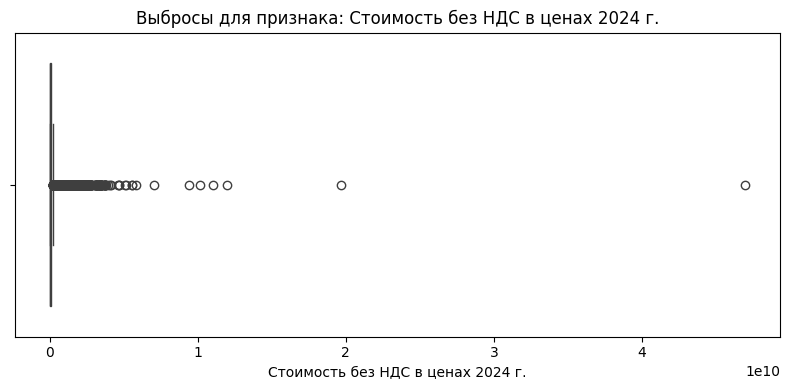

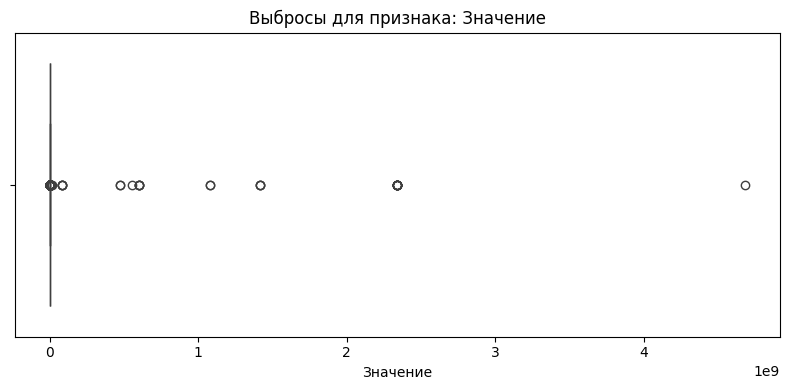

In [41]:
for col in num_cols:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=df[col])
    plt.title(f"Выбросы для признака: {col}")
    plt.tight_layout()
    plt.show()

Распределения я смотрел, чтобы убедиться, что корреляция Пирсона нам не подойдет. Стоимость и значение свойств имеют скошенное распределение, а "Лет в эксплуатации" за счет меньше размаха можно увидеть сами столбики и правый хвост.

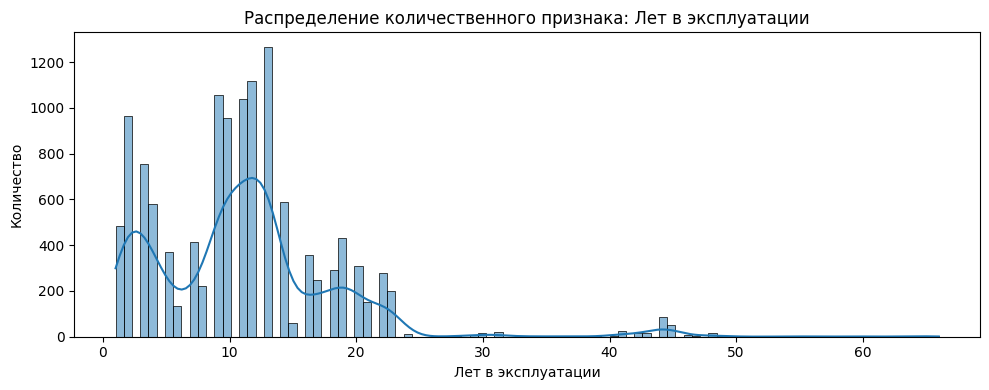

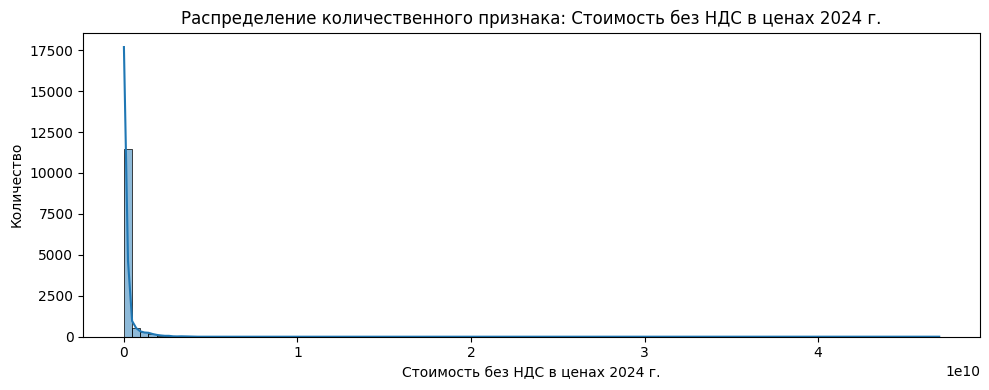

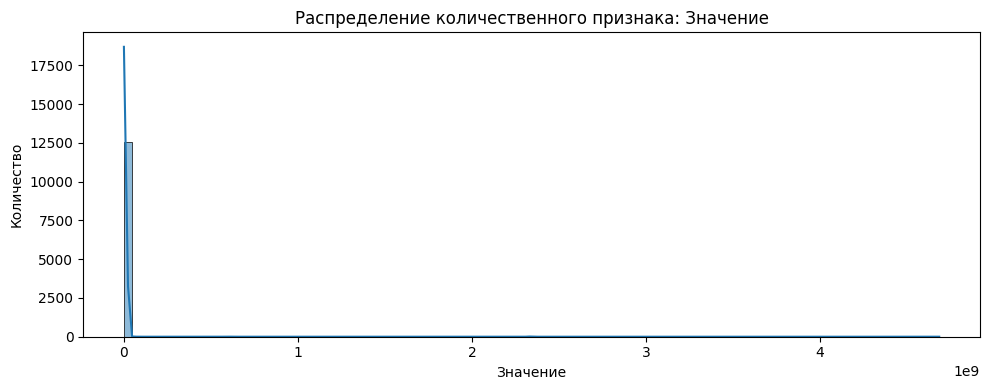

In [42]:
for col in num_cols:
    plt.figure(figsize=(10,4))
    sns.histplot(df[col], bins=100, kde=True)
    plt.title(f"Распределение количественного признака: {col}")
    plt.xlabel(col)
    plt.ylabel("Количество")
    plt.tight_layout()
    plt.show()

Диаграмму рассеяния тоже смотрел для выбора метода Корреляции. Разумеется, никакой линейной связи не наблюдается.

<Figure size 2000x2000 with 0 Axes>

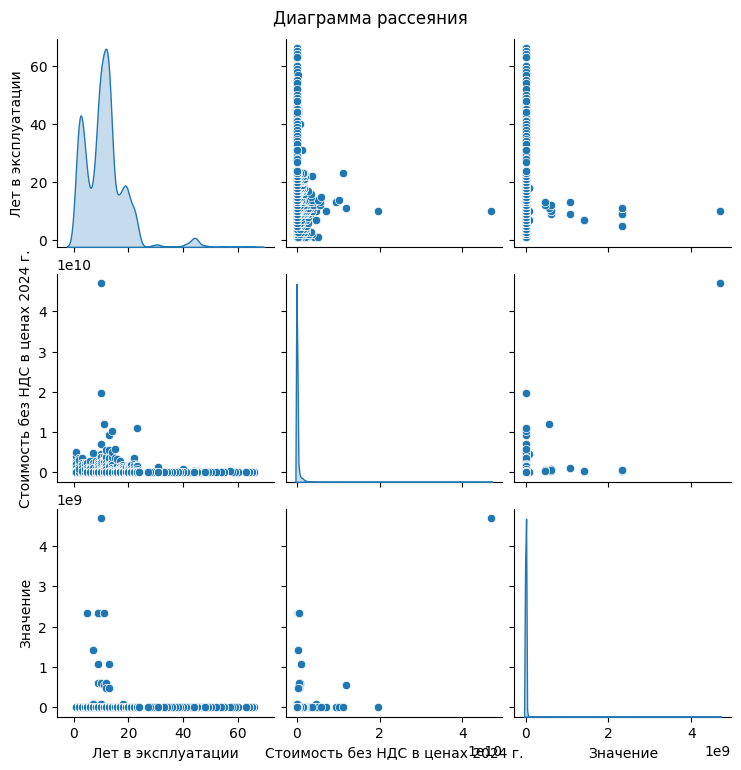

In [43]:
plt.figure(figsize=(20, 20))
sns.pairplot(df[num_cols], diag_kind="kde")
plt.suptitle("Диаграмма рассеяния", y=1.02)
plt.show()

Из матрицы корреляции видно, что между признаками наблюдаются только слабые связи, что не страшно, так как машинное обучение может справиться и без этого.

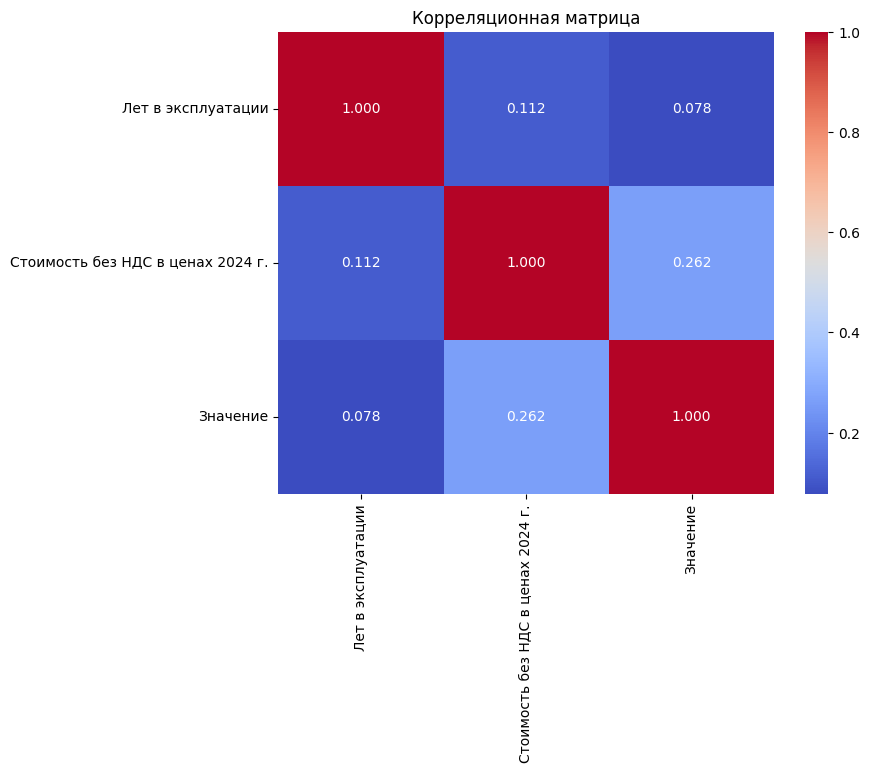

In [44]:
df_corr = df[num_cols].copy()

corr_spearman = df_corr.corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(corr_spearman, annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Корреляционная матрица")
plt.show()

Матрица корреляций для категориальных признаков меня обрадовала. Есть сильная связь между Регионами, Округами и Организациями (Регионы и Округи все-таки я объединил). Также сильная связь между Наименованием, Основным свойством и единицами измерения.

In [45]:
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    return np.sqrt(phi2 / min(k-1, r-1))

In [46]:
corr_matrix = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)

for col1 in cat_cols:
    for col2 in cat_cols:
        if col1 == col2:
            corr_matrix.loc[col1, col2] = 1.0
        else:
            corr_matrix.loc[col1, col2] = cramers_v(df[col1], df[col2])

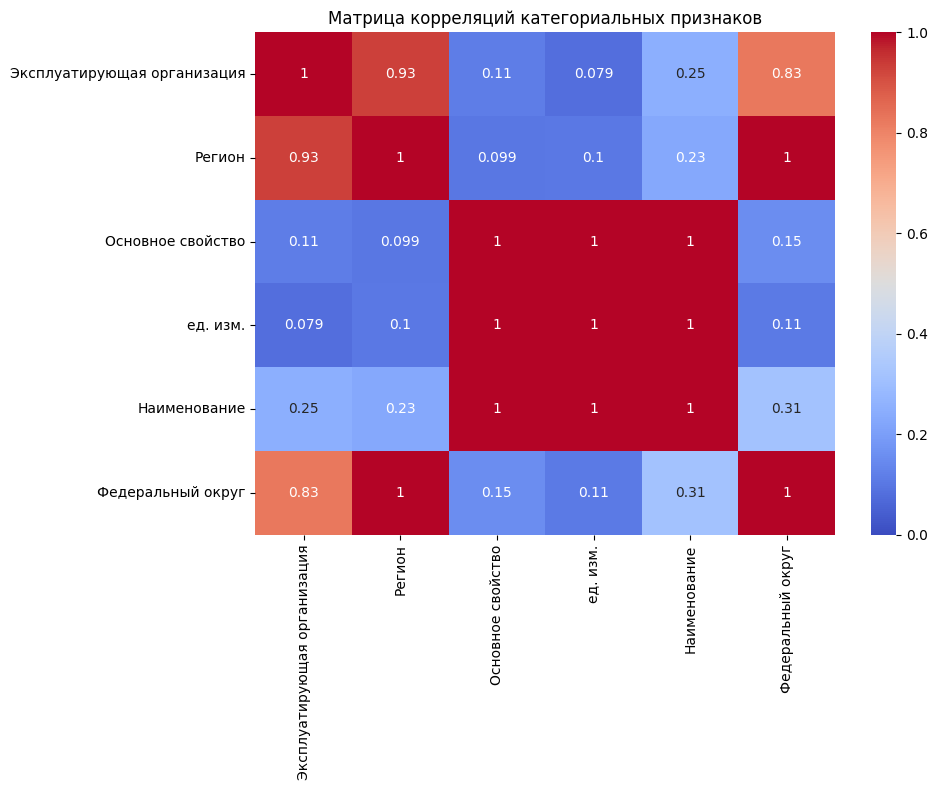

In [47]:
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix.astype(float), annot=True, cmap="coolwarm", vmin=0, vmax=1)
plt.title("Матрица корреляций категориальных признаков")
plt.tight_layout()
plt.show()

# Кластеризация

Следующим шагом я решил провести кластеризацию, чтобы понять, как объекты данных группируются по признакам. В исходном датасете очень много уникальных Наименований (379), а наблюдений 12 608, логично было сначала агрегировать данные по Наименованию, усреднив числовые признаки и выбрав моду для категориальных. Это позволило уменьшить размерность и упростить визуальное и количественное изучение структуры данных.

In [48]:
agg_df = df.groupby('Наименование').agg({
    'Значение': 'median',                
    'Лет в эксплуатации': 'median',      
    'Стоимость без НДС в ценах 2024 г.': 'median', 
    'Основное свойство': lambda x: x.mode()[0], 
    'ед. изм.': lambda x: x.mode()[0],          
    'Федеральный округ': lambda x: x.mode()[0], 
    'Регион': lambda x: x.mode()[0],           
    'Эксплуатирующая организация': lambda x: x.mode()[0]  
}).reset_index()

agg_df

,Наименование,Значение,Лет в эксплуатации,Стоимость без НДС в ценах 2024 г.,Основное свойство,ед. изм.,Федеральный округ,Регион,Эксплуатирующая организация
0,База рукавная,7.400,22.0,4.201589e+07,площадь общая,м2,Округ_7,Регион_49,Организация_13
1,Башня антенная,38.500,2.0,6.155252e+06,высота,м,Округ_8,Регион_42,Организация_10
2,Башня водопроводная (водонапорная),50.000,22.0,5.661054e+06,объем,м3,Округ_9,Регион_37,Организация_12
3,Башня учебная пожарная,13.710,19.0,8.880318e+06,высота,м,Округ_2,Регион_30,Организация_2
4,Биологический пруд,5122.280,17.0,1.381323e+07,площадь поверхности теплообмена,м2,Округ_6,Регион_45,Организация_14
...,...,...,...,...,...,...,...,...,...
374,Элементы благоустройства: малые архитектурные ...,11130.000,44.0,6.012271e+07,площадь общая,м2,Округ_6,Регион_45,Организация_14
375,Эстакада досмотра автотранспорта,33.000,9.0,4.242925e+07,длина,м,Округ_4,Регион_33,Организация_16
376,Эстакада коммуникаций внеплощадочных,153.000,12.0,1.616420e+07,протяженность,м,Округ_4,Регион_33,Организация_16
377,Эстакада сетей внутриплощадочных,1041.295,9.0,1.112502e+08,протяженность,м,Округ_4,Регион_33,Организация_16


Числовые признаки были нормализованы через StandardScaler, чтобы привести их к одинаковой шкале. Категориальные признаки преобразованы в частотное кодирование, заменяя каждую категорию на долю её встречаемости в данных.

In [49]:
num_cols = ['Значение', 'Лет в эксплуатации', 'Стоимость без НДС в ценах 2024 г.']
scaler = StandardScaler()
agg_df[num_cols] = scaler.fit_transform(agg_df[num_cols])

cat_cols = ['Основное свойство', 'ед. изм.', 'Федеральный округ', 'Регион', 'Эксплуатирующая организация']
for col in cat_cols:
    freq = agg_df[col].value_counts(normalize=True)
    agg_df[col] = agg_df[col].map(freq)

Я использовал DBSCAN и HDBSCAN с Gower, потому что данные смешанные. DBSCAN/HDBSCAN хорошо работают с плотностными кластерами и автоматически выделяют шум, а Gower позволяет корректно считать расстояния между объектами с разными типами признаков, что делает кластеризацию более адекватной для структуры данных.

Далее был проведён перебор значений параметра eps для алгоритма DBSCAN с метрикой Manhattan на объединённых признаках. Для каждого значения eps вычислялись ключевые метрики кластеризации - число образованных кластеров, доля шума и коэффициент силуэта, что позволило оценить плотность и качество кластеров. Результаты визуализированы на графиках зависимости силы silhouetteа, числа кластеров и доли шума от eps, чтобы подобрать оптимальное значение параметра для дальнейшей кластеризации.

In [50]:
X = agg_df[num_cols + cat_cols].values

eps_values = np.linspace(0.1, 2.0, 20)
results = []

for eps in eps_values:
    dbscan = DBSCAN(eps=eps, min_samples=5, metric='manhattan')
    labels = dbscan.fit_predict(X)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_ratio = list(labels).count(-1) / len(labels)
    
    if n_clusters > 1:
        score = silhouette_score(X, labels)
    else:
        score = -1
    
    results.append({
        "eps": eps,
        "n clusters": n_clusters,
        "noise": round(noise_ratio, 3),
        "silhouette": round(score, 3)
    })

results_df = pd.DataFrame(results)
results_df.sort_values("silhouette", ascending=False)

,eps,n clusters,noise,silhouette
8,0.9,2,0.032,0.679
7,0.8,2,0.034,0.676
6,0.7,2,0.047,0.655
5,0.6,3,0.071,0.451
4,0.5,2,0.129,0.404
3,0.4,2,0.211,0.312
2,0.3,11,0.327,0.000
1,0.2,9,0.612,-0.210
0,0.1,7,0.823,-0.425
14,1.5,1,0.008,-1.000


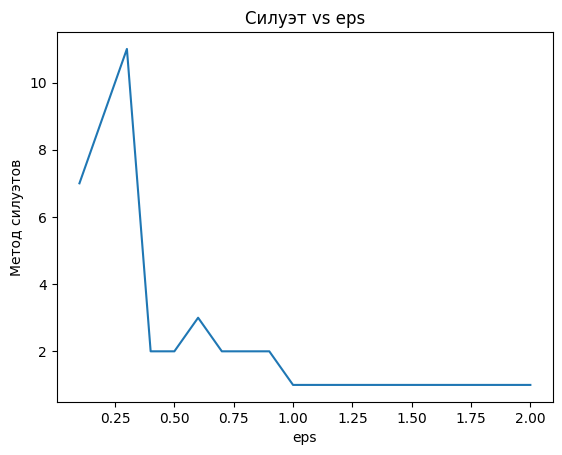

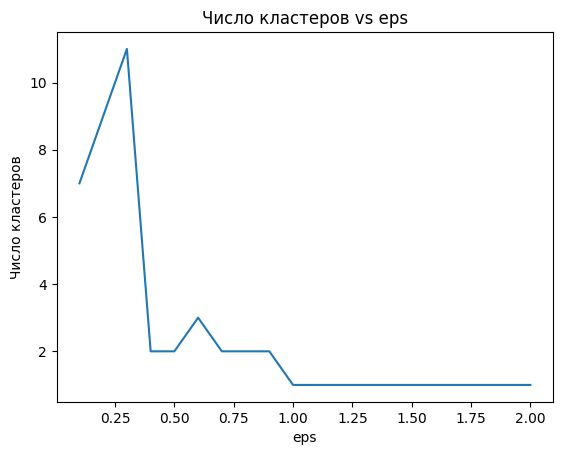

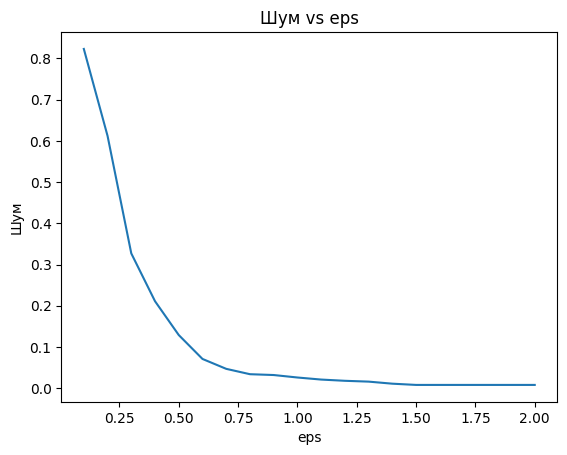

In [51]:
plt.figure()
plt.plot(results_df["eps"], results_df["n clusters"])
plt.xlabel("eps")
plt.ylabel("Метод силуэтов")
plt.title("Силуэт vs eps")
plt.show()

plt.figure()
plt.plot(results_df["eps"], results_df["n clusters"])
plt.xlabel("eps")
plt.ylabel("Число кластеров")
plt.title("Число кластеров vs eps")
plt.show()

plt.figure()
plt.plot(results_df["eps"], results_df["noise"])
plt.xlabel("eps")
plt.ylabel("Шум")
plt.title("Шум vs eps")
plt.show()

Результаты показали, что при выбранном eps = 0.9 алгоритм DBSCAN выделил всего один крупный кластер и несколько выбросов, что указывает на слабую дифференциацию по выбранным числовым признакам при этом методе.

DBSCAN_cluster
-1      3
 0    376
Name: count, dtype: int64


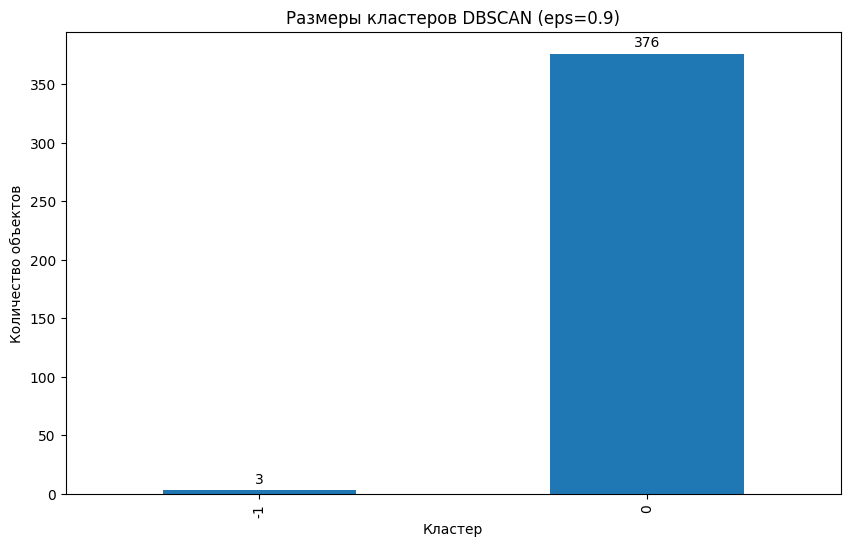

In [52]:
X = agg_df[num_cols].values 

best_eps = 0.9
db = DBSCAN(eps=best_eps, min_samples=5)
labels = db.fit_predict(X)

agg_df['DBSCAN_cluster'] = labels

cluster_counts = agg_df['DBSCAN_cluster'].value_counts().sort_index()
print(cluster_counts)

plt.figure(figsize=(10,6))
ax = cluster_counts.plot(kind='bar')
ax.bar_label(ax.containers[0], padding=3)
plt.xlabel("Кластер")
plt.ylabel("Количество объектов")
plt.title(f"Размеры кластеров DBSCAN (eps={best_eps})")
plt.show()

Потом была проведена кластеризация с использованием HDBSCAN на матрице Gower, что позволило учитывать одновременно числовые и категориальные признаки. Сначала я перебрал различные значения параметра min_cluster_size, оценивая для каждого числа кластеров, долю шума и силуэт, чтобы понять, при каких параметрах формируются стабильные и качественные кластеры. Выбор min_cluster_size = 3 дал наибольшее число кластеров с минимальным шумом и относительно высоким коэффициентом силуэта, что говорит о том, что данные содержат несколько плотных групп, которые можно выделить без сильного объединения или потери структуры.

In [53]:
X_gower = gower.gower_matrix(agg_df[num_cols + cat_cols])

X_gower = X_gower.astype(np.float64)

results = []

for size in range(2, 21):
    clusterer = hdbscan.HDBSCAN(min_cluster_size=size, metric='precomputed')
    labels = clusterer.fit_predict(X_gower)
    
    mask = labels != -1
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    
    if mask.sum() > 1 and n_clusters > 1:
        sil_score = silhouette_score(X_gower[np.ix_(mask, mask)],
                                     labels[mask],
                                     metric='precomputed')
    else:
        sil_score = np.nan
    
    results.append({
        'size': size,
        'n clusters': n_clusters,
        'noise': np.mean(labels == -1),
        'silhouette': sil_score
    })

results_df = pd.DataFrame(results)
results_df['ratio'] = results_df['silhouette'] / results_df['noise']
results_df.sort_values("ratio", ascending=False)

,size,n clusters,noise,silhouette,ratio
0,2,55,0.216359,0.561169,2.593694
1,3,37,0.279683,0.666294,2.382314
18,20,4,0.263852,0.614169,2.327701
15,17,4,0.263852,0.612233,2.320362
16,18,4,0.263852,0.612233,2.320362
17,19,4,0.266491,0.615844,2.310939
7,9,8,0.269129,0.616861,2.292062
8,10,7,0.279683,0.598737,2.140768
2,4,29,0.321900,0.651639,2.024353
9,11,6,0.313984,0.600036,1.911040


In [54]:
best_cluster_size = results_df.loc[
    results_df["ratio"].idxmax(),
    "size"
]

best_cluster_size

2

In [55]:
clusterer = hdbscan.HDBSCAN(min_cluster_size=best_cluster_size, metric='precomputed')
agg_df['HDBSCAN_cluster'] = clusterer.fit_predict(X_gower)

cluster_counts = agg_df['HDBSCAN_cluster'].value_counts().sort_index()
cluster_counts

HDBSCAN_cluster
-1     82
 0      4
 1      8
 2      6
 3      9
 4      3
 5      3
 6      5
 7      7
 8      3
 9      7
 10     5
 11    17
 12     8
 13     4
 14     6
 15     5
 16    10
 17     9
 18    10
 19     3
 20     4
 21     2
 22     7
 23     4
 24     2
 25     5
 26     8
 27     4
 28     7
 29     8
 30     3
 31     4
 32     5
 33     3
 34     5
 35     5
 36     3
 37     3
 38     4
 39     8
 40     2
 41     4
 42     6
 43     3
 44     3
 45     3
 46     7
 47     9
 48     4
 49     6
 50     3
 51     4
 52     7
 53     5
 54     5
Name: count, dtype: int64

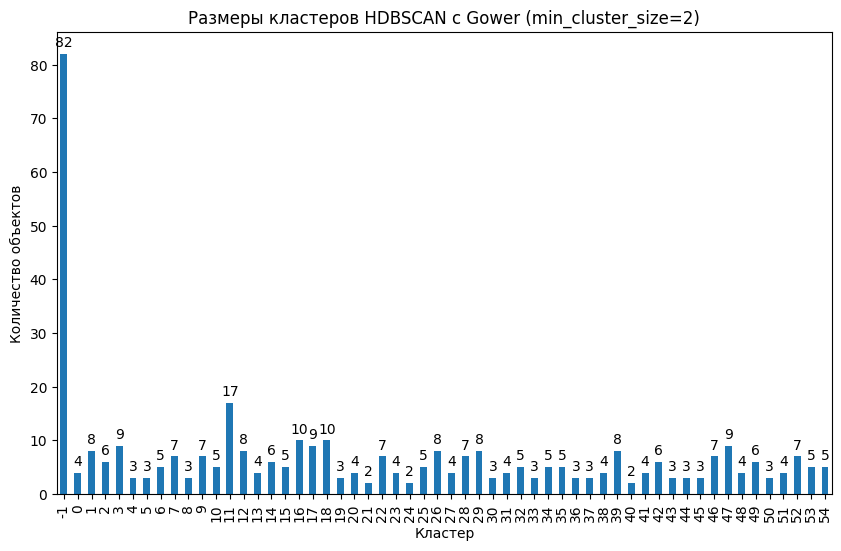

In [56]:
plt.figure(figsize=(10,6))
ax=cluster_counts.plot(kind='bar')
ax.bar_label(ax.containers[0], padding=3)
plt.xlabel("Кластер")
plt.ylabel("Количество объектов")
plt.title("Размеры кластеров HDBSCAN с Gower (min_cluster_size=2)")
plt.show()

Результаты кластеризации с Gower и HDBSCAN показали, что объекты распределяются по нескольким плотным кластерам, при этом большинство наблюдений оказывается сгруппировано в определённые кластеры, а редкие комбинации признаков выделяются как шум. Это говорит о том, что структура данных достаточно выражена, и имеет смысл проводить дальнейшую классификацию, используя исходные признаки и, при желании, кластеры как дополнительный признак для улучшения предсказательной модели.

Далее я применил t-SNE для понижения размерности и визуализации структуры данных, полученной после кластеризации. Исходные признаки имеют смешанную природу, ранее был использован Gower, а затем выполнено преобразование через PCA. PCA снижает шум и ускоряет работу t-SNE, сохраняя при этом основную структуру расстояний

In [57]:
pca = PCA(n_components=X.shape[1], random_state=123)
X_pca = pca.fit_transform(X_gower)

t-SNE был выбран, так как он хорошо выявляет локальные структуры и позволяет визуально оценить, насколько объекты одного кластера действительно находятся близко друг к другу в пространстве признаков.  Результат t-SNE сильно зависит от гиперпараметров, в первую очередь от perplexity (размер локального окружения) и learning rate, поэтому был выполнен их перебор

Для каждой комбинации параметров рассчитывался коэффициент силуэта и шум. Была введена метрика — отношение силуэта к доле шума, чтобы одновременно учитывать компактность кластеров и их чистоту

In [58]:
perplexities = range(2, 102, 5)          
learning_rates = [50, 100, 200, 300, 500, 800, 1000]

results = []

labels = agg_df['HDBSCAN_cluster'].values
noise_ratio = np.mean(labels == -1)  

mask = labels != -1 

for p in perplexities:
    for lr in learning_rates:

        tsne = TSNE(
            n_components=2,
            perplexity=p,
            learning_rate=lr,
            init='pca',
            max_iter=250,
            n_iter_without_progress=25,
            random_state=123
        )

        X_tsne = tsne.fit_transform(X_pca)

        if np.sum(mask) > 1:
            score = silhouette_score(X_tsne[mask], labels[mask])
        else:
            score = np.nan

        results.append({
            "perplexity": p,
            "learning rate": lr,
            "silhouette": score,
            "noise": noise_ratio,
            "ratio": score / (noise_ratio + 1e-5)
        })

results_df = pd.DataFrame(results)

results_df.sort_values("ratio", ascending=False)

,perplexity,learning rate,silhouette,noise,ratio
0,2,50,0.402347,0.216359,1.859544
126,92,50,0.251374,0.216359,1.161786
133,97,50,0.214403,0.216359,0.990916
28,22,50,0.209471,0.216359,0.968120
119,87,50,0.202263,0.216359,0.934807
...,...,...,...,...,...
137,97,500,-0.513636,0.216359,-2.373891
122,87,300,-0.515209,0.216359,-2.381163
136,97,300,-0.522723,0.216359,-2.415887
114,82,200,-0.523061,0.216359,-2.417453


In [59]:
best_perplexity = results_df.loc[
    results_df["ratio"].idxmax(),
    "perplexity"
]

best_perplexity

2

In [60]:
best_lr = results_df.loc[
    results_df["ratio"].idxmax(),
    "learning rate"
]

best_lr

50

Оптимальными оказались значения perplexity = 2 и learning rate = 50. Низкое значение perplexity указывает на то, что структура данных носит локальный характер, и кластеры формируются за счёт близких соседей, а не глобальных зависимостей

In [61]:
tsne = TSNE(
    n_components=2,
    perplexity=best_perplexity,
    learning_rate=best_lr,
    init='pca',
    random_state=123
)

X_tsne = tsne.fit_transform(X_pca)

In [62]:
tsne_df = pd.DataFrame({
    "t-SNE1": X_tsne[:,0],
    "t-SNE2": X_tsne[:,1],
    "cluster": agg_df["HDBSCAN_cluster"].astype(str),
    "Наименование": agg_df["Наименование"]
})

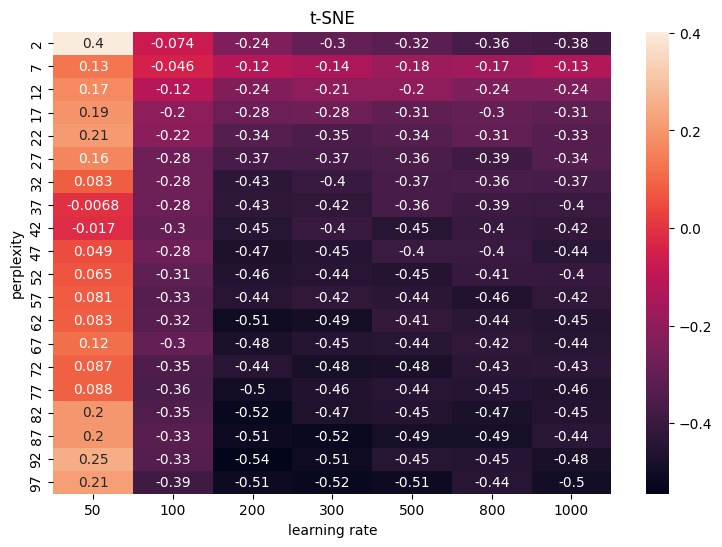

In [63]:
pivot = results_df.pivot(
    index="perplexity",
    columns="learning rate",
    values="silhouette"
)

plt.figure(figsize=(9,6))
sns.heatmap(pivot, annot=True)

plt.title("t-SNE")
plt.xlabel("learning rate")
plt.ylabel("perplexity")

plt.show()

Визуализация t-SNE показала, что часть кластеров действительно хорошо отделена в пространстве, однако присутствует и значительное пересечение, что согласуется с умеренными значениями метрик качества. Признаки не всегда позволяют однозначно разделить классы, и в данных присутствует сложная и перекрывающаяся структура

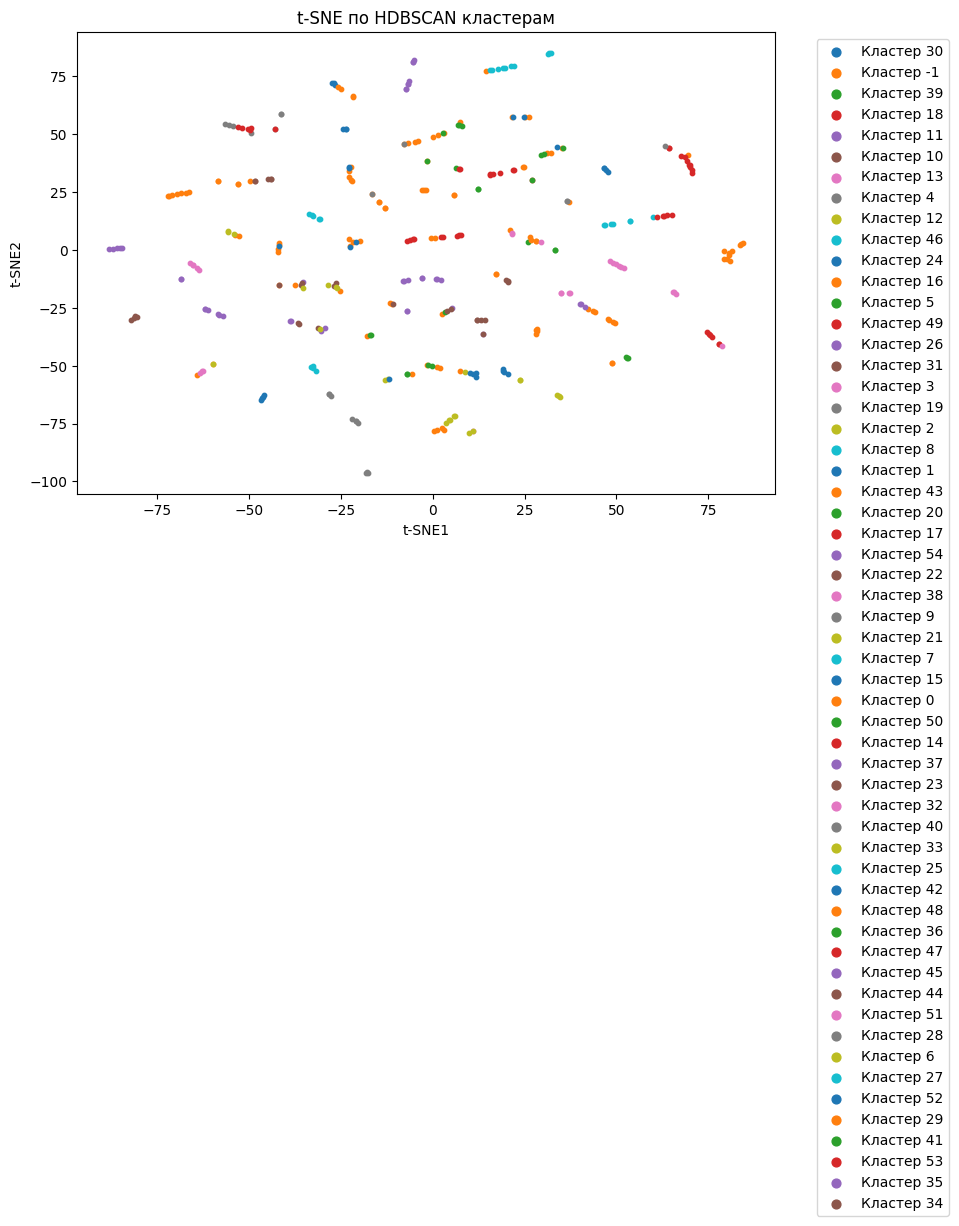

In [64]:
plt.figure(figsize=(9, 6))

clusters = tsne_df["cluster"].unique()

for cluster in clusters:
    mask = tsne_df["cluster"] == cluster
    plt.scatter(
        tsne_df.loc[mask, "t-SNE1"],
        tsne_df.loc[mask, "t-SNE2"],
        s=10,
        label=f"Кластер {cluster}"
    )

plt.title("t-SNE по HDBSCAN кластерам")
plt.xlabel("t-SNE1")
plt.ylabel("t-SNE2")
plt.legend(markerscale=2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Детектирование аномалий

Потом я применил Isolation Forest для выявления аномальных объектов в данных после кластеризации. Модель была обучена на агрегированных признаках с использованием оптимальных гиперпараметров, подобранных через сетку параметров: количество деревьев, доля выборки и признаков, а также уровень contamination (ожидаемая доля аномалий)

In [65]:
labels = agg_df['HDBSCAN_cluster']
normal_mask = labels.isin(labels.value_counts()[labels.value_counts() >= 10].index)
rare_mask = ~normal_mask

Аномалии определялись как объекты, находящиеся далеко от основной плотности данных. Для оценки качества выделения использовались два критерия: коэффициент силуэта и шум. Были исключены комбинации с большим числом шумных объектов. В результате оптимальная модель выделила около 3% аномалий, большинство из которых сосредоточено в редких кластерах или на периферии плотных кластеров

In [66]:
param_grid = {
    "n_estimators": [100, 150, 200, 250, 300],
    "contamination": [0.03, 0.05, 0.07, 0.1, 0.15],
    "max_samples": [0.3, 0.5, 0.7],
    "max_features": [0.3, 0.5, 0.7],
}

results = []

for params in ParameterGrid(param_grid):

    iso = IsolationForest(
        **params,
        random_state=123,
        n_jobs=-1
    )

    iso.fit(X_gower)

    preds = iso.predict(X_gower)

    noise_ratio = np.mean(preds == -1)

    if noise_ratio > 0.2:
        continue

    mask = preds != -1

    if mask.sum() > 10:
        try:
            sil = silhouette_score(
                X_pca[mask],
                agg_df['HDBSCAN_cluster'][mask]
            )
        except:
            sil = np.nan
    else:
        sil = np.nan

    results.append({
        **params,
        "noise": noise_ratio,
        "silhouette": sil,
        "ratio": sil / noise_ratio if noise_ratio > 0 else np.nan
    })

results_df = pd.DataFrame(results)
results_df.sort_values("ratio", ascending=False)

,contamination,max_features,max_samples,n_estimators,noise,silhouette,ratio
15,0.03,0.5,0.3,100,0.031662,0.158558,5.007781
0,0.03,0.3,0.3,100,0.031662,0.149175,4.711428
16,0.03,0.5,0.3,150,0.031662,0.145177,4.585180
26,0.03,0.5,0.7,150,0.031662,0.144483,4.563247
32,0.03,0.7,0.3,200,0.031662,0.141467,4.467997
...,...,...,...,...,...,...,...
198,0.15,0.5,0.3,250,0.150396,0.121437,0.807450
213,0.15,0.7,0.3,250,0.150396,0.121034,0.804769
201,0.15,0.5,0.5,150,0.150396,0.120568,0.801670
181,0.15,0.3,0.3,150,0.150396,0.118396,0.787230


In [67]:
best_params = results_df.sort_values("ratio", ascending=False).iloc[0]
best_params

contamination      0.030000
max_features       0.500000
max_samples        0.300000
n_estimators     100.000000
noise              0.031662
silhouette         0.158558
ratio              5.007781
Name: 15, dtype: float64

In [68]:
best_params_dict = best_params.drop(["noise", "silhouette", "ratio"]).to_dict()
best_params_dict["n_estimators"] = int(best_params_dict["n_estimators"])
best_params_dict

{'contamination': 0.03,
 'max_features': 0.5,
 'max_samples': 0.3,
 'n_estimators': 100}

In [69]:
best_iso = IsolationForest(
    **best_params_dict,
    random_state=123,
    n_jobs=-1
)

best_iso.fit(X_gower)

,n_estimators,100
,max_samples,0.3
,contamination,0.03
,max_features,0.5
,bootstrap,False
,n_jobs,-1
,random_state,123
,verbose,0
,warm_start,False


In [70]:
anomaly_scores = iso.decision_function(X_gower)
preds = iso.predict(X_gower)

In [71]:
agg_df['anomaly'] = preds

pd.crosstab(
    agg_df['HDBSCAN_cluster'],
    agg_df['anomaly']
)

anomaly,-1,1
HDBSCAN_cluster,,
-1,18,64
0,4,0
1,3,5
2,6,0
3,9,0
4,3,0
5,0,3
6,1,4
7,0,7


In [72]:
tsne_df = pd.DataFrame(X_tsne, columns=['x', 'y'])
tsne_df['cluster'] = agg_df['HDBSCAN_cluster'].values
tsne_df['anomaly'] = agg_df['anomaly'].values
tsne_df['Наименование'] = agg_df['Наименование'].values

Для визуализации аномалии были нанесены на проекцию t-SNE по тем же признакам, что и кластеры. На графиках видно, что крупные и частые кластеры практически не содержат аномалий, тогда как редкие кластеры могут состоять преимущественно из выбросов, а часть аномалий внутри крупных кластеров указывает на скрытые отклонения

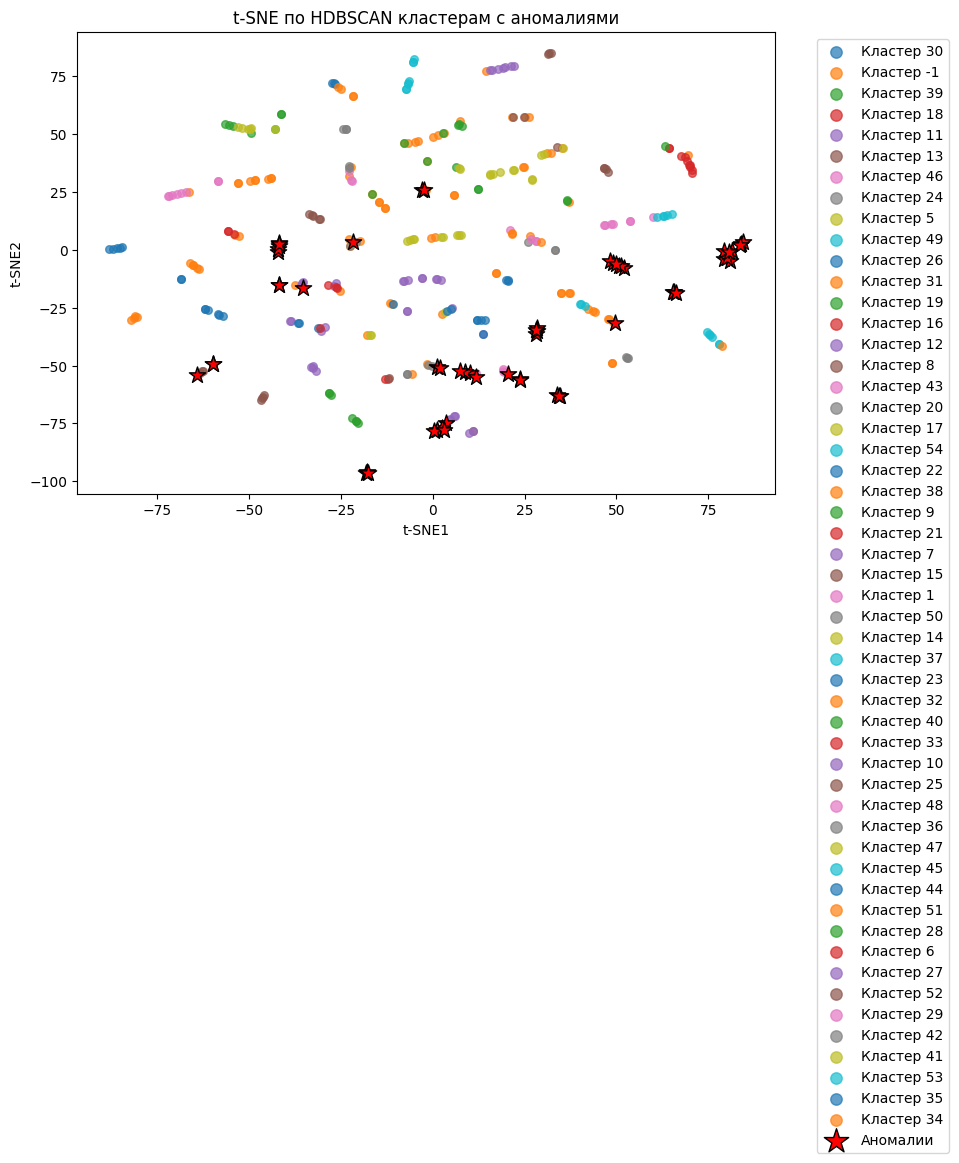

In [73]:
plt.figure(figsize=(9, 6))

normal_mask = tsne_df["anomaly"] != -1
normal_clusters = tsne_df.loc[normal_mask, "cluster"].unique()

for cluster in normal_clusters:
    cluster_mask = (tsne_df["cluster"] == cluster) & normal_mask
    plt.scatter(
        tsne_df.loc[cluster_mask, "x"],
        tsne_df.loc[cluster_mask, "y"],
        s=30,
        label=f"Кластер {cluster}",
        alpha=0.7
    )

anomalies = tsne_df[tsne_df["anomaly"] == -1]
plt.scatter(
    anomalies["x"],
    anomalies["y"],
    marker="*",
    s=150,
    c="red",
    edgecolors='black',
    label="Аномалии"
)

plt.title("t-SNE по HDBSCAN кластерам с аномалиями")
plt.xlabel("t-SNE1")
plt.ylabel("t-SNE2")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', markerscale=1.5)
plt.tight_layout()
plt.show()

Анализ доли аномалий в каждом кластере показал ярко выраженную неоднородность. Некоторые кластеры, например 0, 2, 3, 4, полностью состояли из аномалий , что указывает на их редкость и малое представительство среди нормальных объектов. Другие кластеры, такие как -1, 1, 16, содержали смешанные группы с высокой долей аномалий (от 22 % до 90 %). Большинство остальных кластеров оказались чистыми

In [74]:
cluster_stats = agg_df.groupby('HDBSCAN_cluster')['anomaly'].apply(
    lambda x: round(np.mean(x == -1), 2)
)

cluster_stats

HDBSCAN_cluster
-1     0.22
 0     1.00
 1     0.38
 2     1.00
 3     1.00
 4     1.00
 5     0.00
 6     0.20
 7     0.00
 8     0.00
 9     0.00
 10    0.20
 11    0.00
 12    0.25
 13    0.00
 14    0.00
 15    0.00
 16    0.90
 17    0.00
 18    0.00
 19    0.00
 20    0.00
 21    0.00
 22    0.00
 23    0.00
 24    0.00
 25    0.00
 26    0.00
 27    0.00
 28    0.00
 29    0.00
 30    0.00
 31    0.00
 32    0.00
 33    0.00
 34    0.00
 35    0.00
 36    0.00
 37    0.00
 38    0.00
 39    0.00
 40    0.00
 41    0.00
 42    0.17
 43    0.00
 44    0.00
 45    0.00
 46    0.00
 47    0.00
 48    0.00
 49    0.00
 50    0.00
 51    0.00
 52    0.00
 53    0.00
 54    0.00
Name: anomaly, dtype: float64

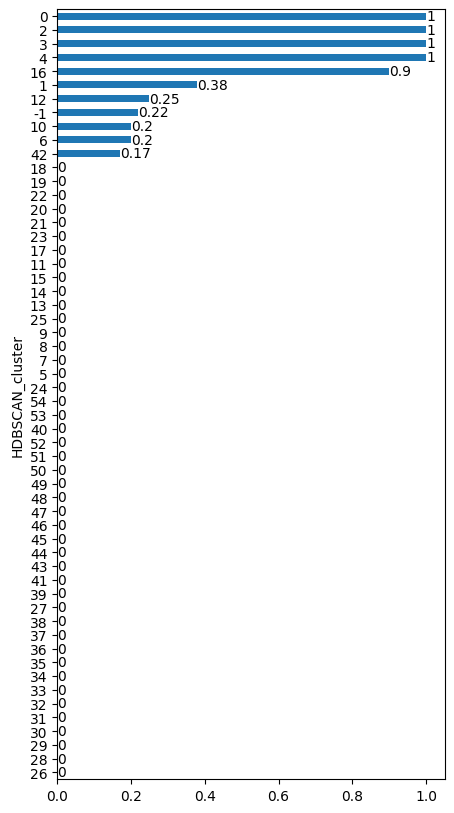

In [75]:
ax=cluster_stats.sort_values().plot(kind='barh', figsize=(5,10))
ax.bar_label(ax.containers[0])
plt.show()

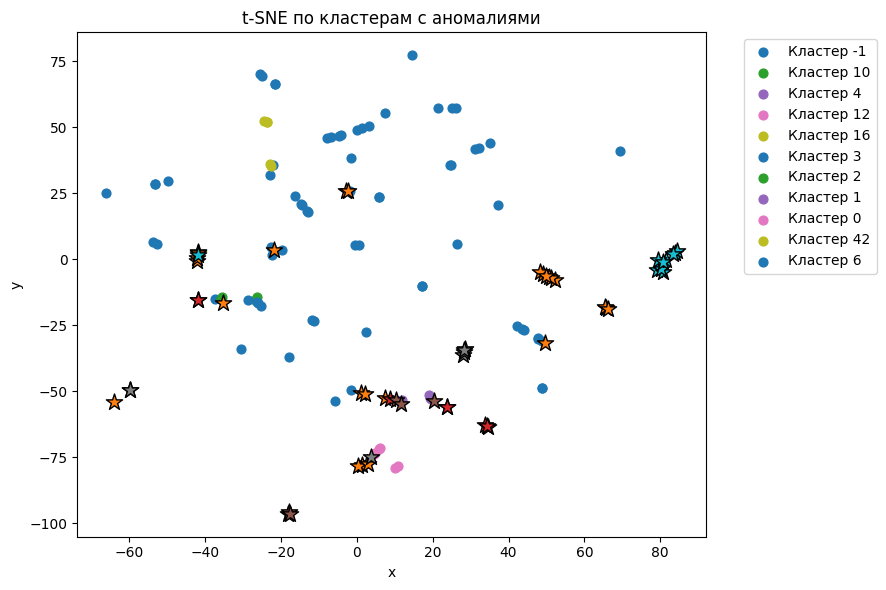

In [76]:
clusters_with_anomalies = tsne_df.loc[tsne_df['anomaly'] == -1, 'cluster'].unique()

filtered_df = tsne_df[tsne_df['cluster'].isin(clusters_with_anomalies)].copy()

plt.figure(figsize=(9, 6))

clusters = filtered_df['cluster'].unique()

for cluster in clusters:
    cluster_data = filtered_df[filtered_df['cluster'] == cluster]
    
    normal = cluster_data[cluster_data['anomaly'] != -1]
    plt.scatter(
        normal['x'],
        normal['y'],
        s=40,
        label=f"Кластер {cluster}"
    )
    
    anomalies = cluster_data[cluster_data['anomaly'] == -1]
    if not anomalies.empty:
        plt.scatter(
            anomalies['x'],
            anomalies['y'],
            marker='*',
            s=150,
            edgecolors='black'
        )

plt.title('t-SNE по кластерам с аномалиями')
plt.xlabel('x')
plt.ylabel('y')

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

После фильтрации аномалий уменьшилось количество объектов в кластере 16 с 10 до 8, а кластер 1 сократился с 8 до 3 объектов. Также общее число кластеров сократилось с 56 до 53. В то же время кластеры без аномалий сохранили размер и структуру. Это демонстрирует, что удаление аномалий повышает чистоту и однородность оставшихся групп

In [77]:
clusterer_before = hdbscan.HDBSCAN(metric='precomputed', min_cluster_size=2)
labels_before = clusterer_before.fit_predict(X_gower)

mask = preds != -1
X_gower_clean = X_gower[np.ix_(mask, mask)]

clusterer_after = hdbscan.HDBSCAN(metric='precomputed', min_cluster_size=2)
labels_after = clusterer_after.fit_predict(X_gower_clean)

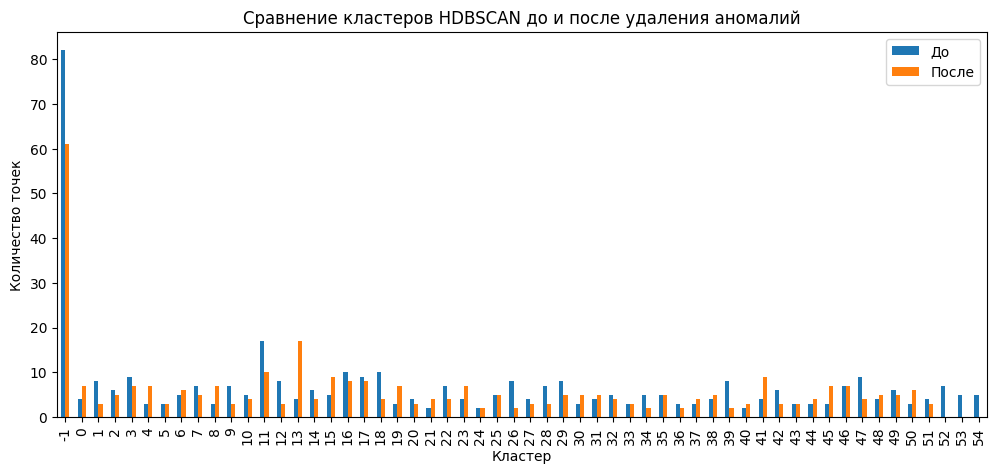

In [78]:
before_counts = pd.Series(labels_before).value_counts().sort_index()
after_counts = pd.Series(labels_after).value_counts().sort_index()

df_compare = pd.DataFrame({
    'До': before_counts,
    'После': after_counts
}).fillna(0)

df_compare.plot(kind='bar', figsize=(12,5))
plt.title("Сравнение кластеров HDBSCAN до и после удаления аномалий")
plt.ylabel("Количество точек")
plt.xlabel("Кластер")
plt.show()

# Преобразование признаков

In [79]:
pt = PowerTransformer(method="yeo-johnson")  

df["стоимость_transformed"] = pt.fit_transform(
    df[["Стоимость без НДС в ценах 2024 г."]]
)

df["log_значение"] = np.log1p(df["Значение"])

df["категории стоимости"] = pd.qcut(
    df["стоимость_transformed"],
    q=5,
    labels=["очень низка", "низкая", "средняя", "высокая", "очень высокая"]
)

df["удельная стоимость"] = df["стоимость_transformed"] - df["log_значение"]

df["износ"] = df["стоимость_transformed"] / (df["Лет в эксплуатации"] + 1)

df.head()

,Эксплуатирующая организация,Регион,Лет в эксплуатации,Стоимость без НДС в ценах 2024 г.,Основное свойство,ед. изм.,Значение,Наименование,Федеральный округ,стоимость_transformed,log_значение,категории стоимости,удельная стоимость,износ
0,Организация_14,Регион_35,1,8.625357e+08,количество точек подключения,шт,1.0,Система управления технологическими процессами...,Округ_1,1.698108,0.693147,очень высокая,1.004960,0.849054
1,Организация_14,Регион_35,1,4.181210e+08,количество точек подключения,шт,6.0,Система управления технологическими процессами...,Округ_1,1.340229,1.945910,очень высокая,-0.605682,0.670114
2,Организация_14,Регион_2,1,3.693608e+08,количество точек подключения,шт,1.0,Система управления технологическими процессами...,Округ_1,1.279010,0.693147,очень высокая,0.585863,0.639505
3,Организация_14,Регион_35,1,4.423769e+07,количество контролируемых параметров,шт,2.0,Система управления энергоснабжением автоматизи...,Округ_1,0.234203,1.098612,средняя,-0.864409,0.117102
4,Организация_14,Регион_35,1,9.558990e+07,количество точек мониторинга,шт,279.0,"Система пожарной сигнализации, контроля загазо...",Округ_1,0.612891,5.634790,высокая,-5.021899,0.306445


In [80]:
base_cols = [
    "стоимость_transformed",
    "log_значение",
    "Лет в эксплуатации",
    "удельная стоимость",
    "износ",
]

for col in base_cols:
    df[f"{col}2"] = df[col] ** 2

for col in base_cols:
    df[f"{col}3"] = df[col] ** 3
    
df.head()

,Эксплуатирующая организация,Регион,Лет в эксплуатации,Стоимость без НДС в ценах 2024 г.,Основное свойство,ед. изм.,Значение,Наименование,Федеральный округ,стоимость_transformed,...,стоимость_transformed2,log_значение2,Лет в эксплуатации2,удельная стоимость2,износ2,стоимость_transformed3,log_значение3,Лет в эксплуатации3,удельная стоимость3,износ3
0,Организация_14,Регион_35,1,8.625357e+08,количество точек подключения,шт,1.0,Система управления технологическими процессами...,Округ_1,1.698108,...,2.883569,0.480453,1,1.009945,0.720892,4.896611,0.333025,1,1.014955,0.612076
1,Организация_14,Регион_35,1,4.181210e+08,количество точек подключения,шт,6.0,Система управления технологическими процессами...,Округ_1,1.340229,...,1.796212,3.786566,1,0.366850,0.449053,2.407335,7.368318,1,-0.222194,0.300917
2,Организация_14,Регион_2,1,3.693608e+08,количество точек подключения,шт,1.0,Система управления технологическими процессами...,Округ_1,1.279010,...,1.635867,0.480453,1,0.343235,0.408967,2.092290,0.333025,1,0.201089,0.261536
3,Организация_14,Регион_35,1,4.423769e+07,количество контролируемых параметров,шт,2.0,Система управления энергоснабжением автоматизи...,Округ_1,0.234203,...,0.054851,1.206949,1,0.747203,0.013713,0.012846,1.325969,1,-0.645889,0.001606
4,Организация_14,Регион_35,1,9.558990e+07,количество точек мониторинга,шт,279.0,"Система пожарной сигнализации, контроля загазо...",Округ_1,0.612891,...,0.375635,31.750854,1,25.219469,0.093909,0.230223,178.909381,1,-126.649623,0.028778


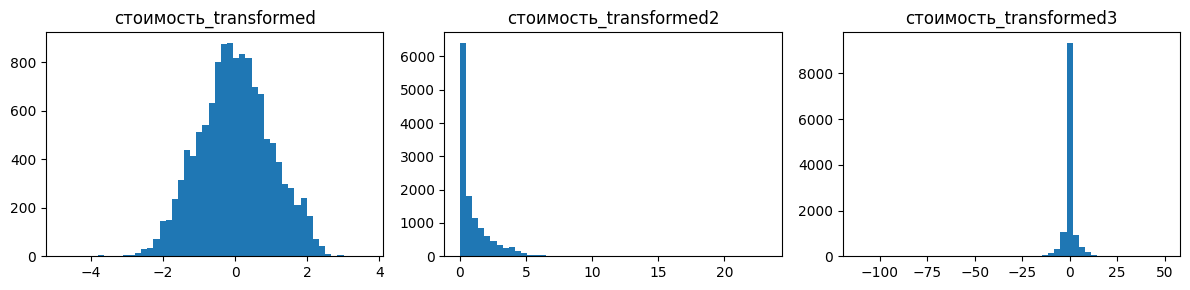

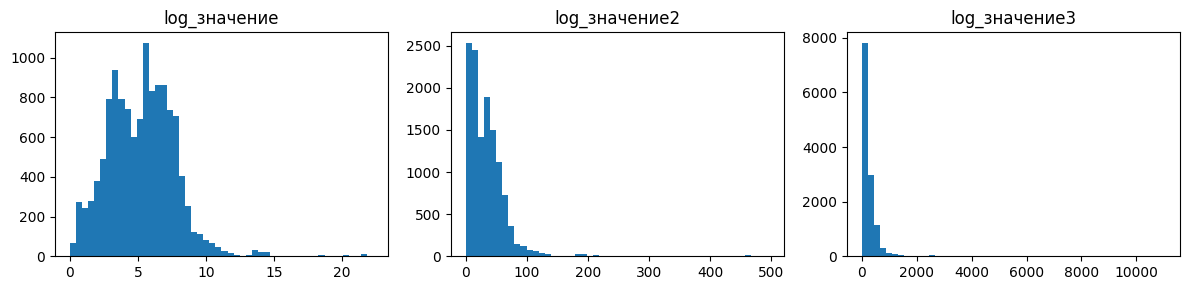

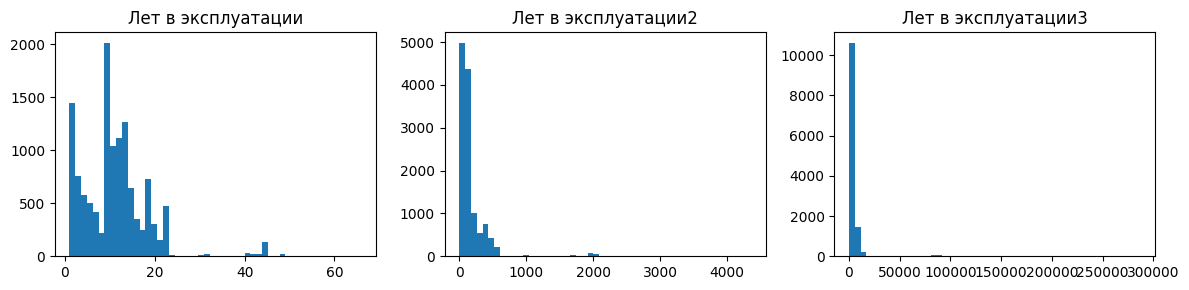

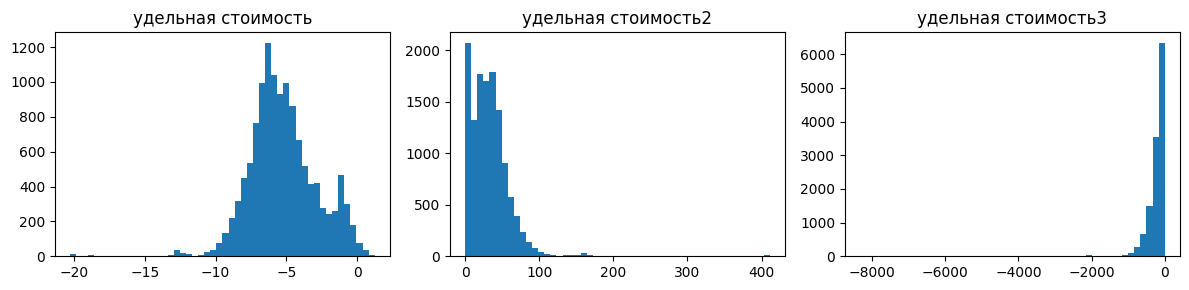

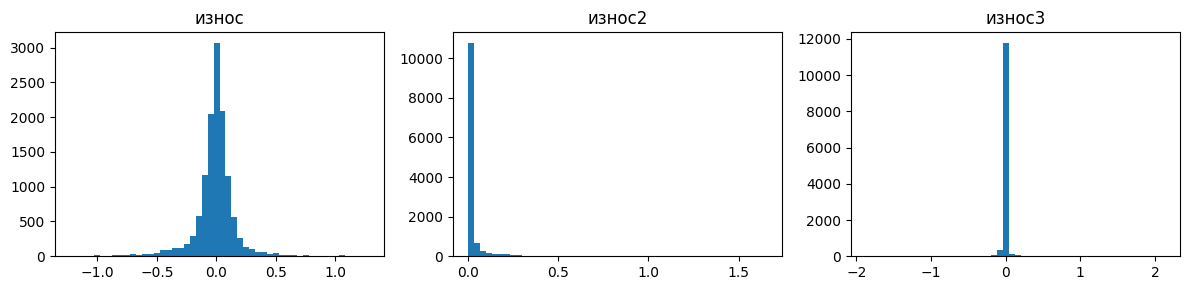

In [81]:
for col in base_cols:
    plt.figure(figsize=(12, 3))
    
    plt.subplot(1, 3, 1)
    plt.hist(df[col].dropna(), bins=50)
    plt.title(col)
    
    plt.subplot(1, 3, 2)
    plt.hist(df[f"{col}2"].dropna(), bins=50)
    plt.title(f"{col}2")
    
    plt.subplot(1, 3, 3)
    plt.hist(df[f"{col}3"].dropna(), bins=50)
    plt.title(f"{col}3")
    
    plt.tight_layout()
    plt.show()

In [82]:
pair_cols = base_cols + \
            [f"{col}2" for col in base_cols] + \
            [f"{col}3" for col in base_cols]

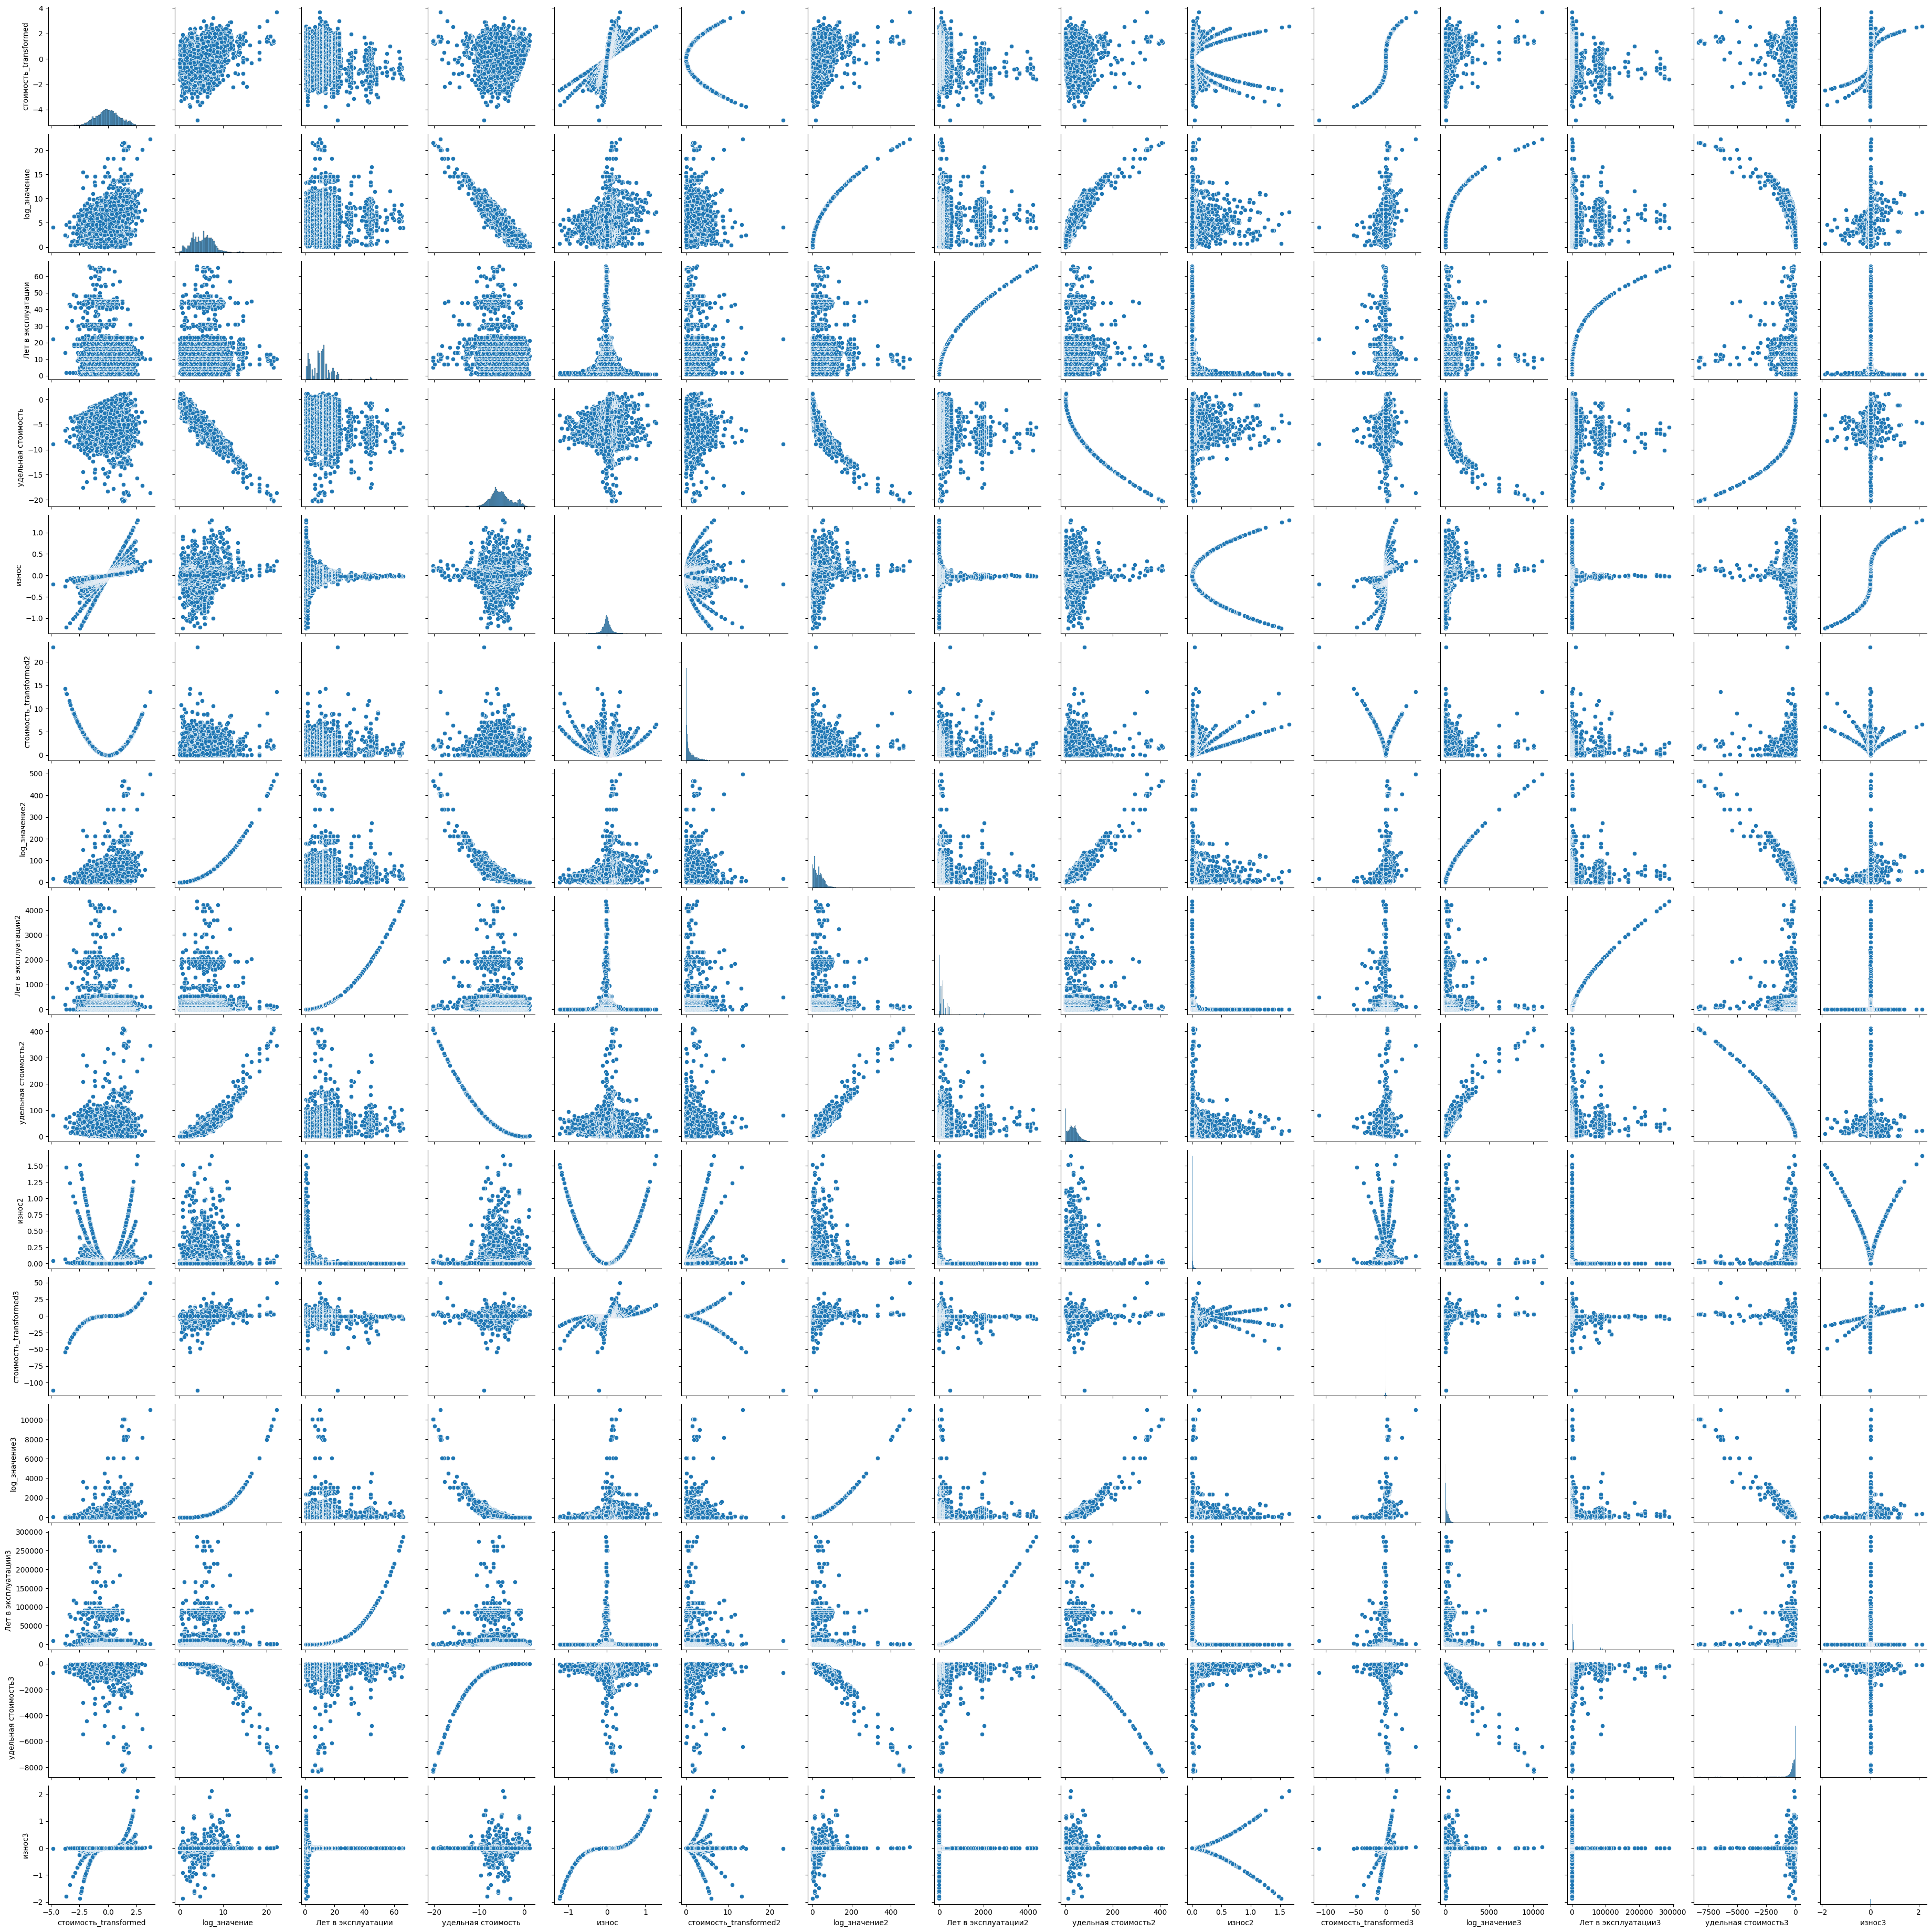

In [83]:
sns.pairplot(df[pair_cols])
plt.show()

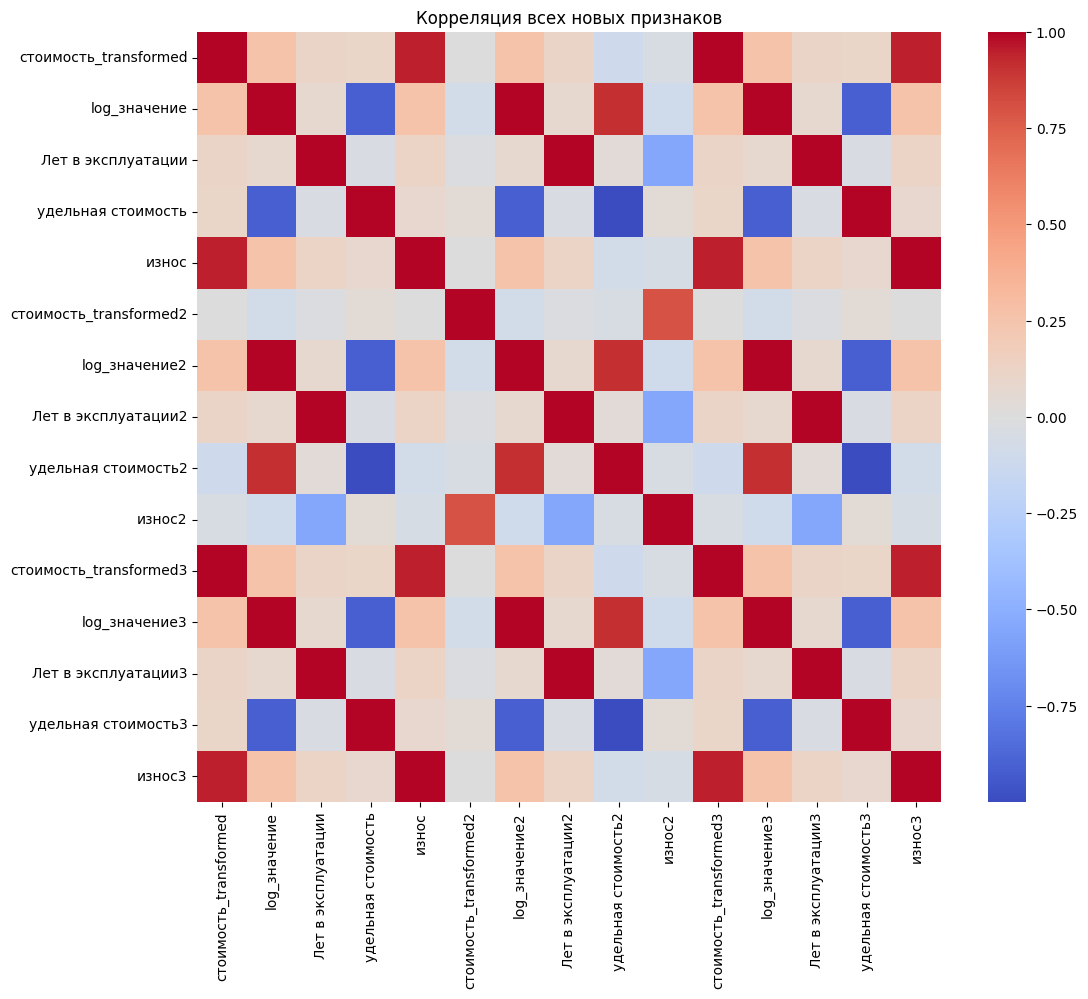

In [84]:
corr_matrix = df[pair_cols].corr(method='spearman')

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap="coolwarm")
plt.title("Корреляция всех новых признаков")
plt.show()

In [85]:
vif_cols = df.select_dtypes(include=["int64", "float64"]).columns

X_vif = df[vif_cols].dropna().copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_vif)

vif_data = pd.DataFrame()
vif_data["feature"] = vif_cols
vif_data["VIF"] = [
    variance_inflation_factor(X_scaled, i)
    for i in range(X_scaled.shape[1])
]

vif_data = vif_data.sort_values("VIF", ascending=False)

vif_data

,feature,VIF
3,стоимость_transformed,inf
4,log_значение,inf
5,удельная стоимость,inf
8,log_значение2,543.792142
10,удельная стоимость2,416.028493
13,log_значение3,339.692739
15,удельная стоимость3,274.849428
9,Лет в эксплуатации2,124.881989
14,Лет в эксплуатации3,54.343494
0,Лет в эксплуатации,25.102581


In [86]:
def compute_vif(df):
    X = df.select_dtypes(include=np.number)
    vif_data = pd.DataFrame()
    vif_data["feature"] = X.columns
    vif_data["VIF"] = [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
    return vif_data.sort_values("VIF", ascending=False)

In [87]:
feature_priority = {
    "Стоимость без НДС в ценах 2024 г.": 0,
    "Значение": 0,

    "стоимость_transformed2": 1,
    "стоимость_transformed3": 1,
    "log_значение2": 1,
    "log_значение3": 1,
    "Лет в эксплуатации2": 1,
    "Лет в эксплуатации3": 1,
    "износ2": 1,
    "износ3": 1,
    "удельная стоимость2": 1,
    "удельная стоимость3": 1,
    
    "стоимость_transformed": 2,
    "log_значение": 2,
    "Лет в эксплуатации": 2,
    "износ": 2,
    "удельная стоимость": 2
}

In [88]:
def feature_selection(df, corr_threshold=0.8, vif_threshold=5, feature_priority=None):
    
    df = df.copy()
    numeric_df = df.select_dtypes(include=np.number)
    
    if feature_priority is None:
        feature_priority = {col: 0 for col in numeric_df.columns}
    
    while True:
        corr_matrix = numeric_df.corr().abs()
        upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
        
        bad_pairs = []
        
        for col in upper.columns:
            for row in upper.index:
                val = upper.loc[row, col]
                if pd.notna(val) and val > corr_threshold:
                    bad_pairs.append((row, col, val))
        
        vif_df = compute_vif(numeric_df)
        high_vif = vif_df[vif_df["VIF"] > vif_threshold]
        
        for _, r in high_vif.iterrows():
            bad_pairs.append((r["feature"], r["feature"], r["VIF"] / vif_threshold))
        
        if len(bad_pairs) == 0:
            break
        
        score = {}
        for f1, f2, _ in bad_pairs:
            score[f1] = score.get(f1, 0) + 1
            if f1 != f2:
                score[f2] = score.get(f2, 0) + 1
        
        score_df = pd.DataFrame({
            "feature": list(score.keys()),
            "count": list(score.values())
        })
        
        score_df["priority"] = score_df["feature"].map(lambda x: feature_priority.get(x, 0))
        
        score_df = score_df.sort_values(
            by=["count", "priority"],
            ascending=[False, True]
        )
        
        drop_col = score_df.iloc[0]["feature"]
        
        print(f"Удаляем: {drop_col} | проблем: {score_df.iloc[0]['count']} | prio={feature_priority.get(drop_col)}")
        
        numeric_df = numeric_df.drop(columns=[drop_col])

    while True:
        corr_matrix = numeric_df.corr().abs()
    
        pairs = []
    
        for i in corr_matrix.columns:
            for j in corr_matrix.columns:
                if i < j:
                    val = corr_matrix.loc[i, j]
                    if pd.notna(val) and val > corr_threshold:
                        pairs.append((i, j, val))
    
        if len(pairs) == 0:
            break
    
        f1, f2, val = max(pairs, key=lambda x: x[2])
    
        prio1 = feature_priority.get(f1, 0)
        prio2 = feature_priority.get(f2, 0)
    
        if prio1 < prio2:
            drop_col = f1
        elif prio2 < prio1:
            drop_col = f2
        else:
            drop_col = f1 if numeric_df[f1].var() < numeric_df[f2].var() else f2
    
        print(f"[CLEANUP] {val:.3f} между {f1} и {f2} → удаляем {drop_col}")
    
        numeric_df = numeric_df.drop(columns=[drop_col])
    
    return numeric_df.columns.tolist()

In [89]:
selected_features = feature_selection(df, corr_threshold=0.8, vif_threshold=5, feature_priority=feature_priority)

Удаляем: log_значение2 | проблем: 6 | prio=1
Удаляем: удельная стоимость2 | проблем: 5 | prio=1
Удаляем: Лет в эксплуатации2 | проблем: 3 | prio=1
Удаляем: log_значение3 | проблем: 2 | prio=1
Удаляем: log_значение | проблем: 2 | prio=2
Удаляем: удельная стоимость | проблем: 1 | prio=2
Удаляем: износ | проблем: 1 | prio=2


In [90]:
to_drop = [col for col in df.select_dtypes(include=np.number).columns if col not in selected_features]
df.drop(columns=to_drop, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12608 entries, 0 to 12658
Data columns (total 17 columns):
 #   Column                             Non-Null Count  Dtype   
---  ------                             --------------  -----   
 0   Эксплуатирующая организация        12608 non-null  object  
 1   Регион                             12608 non-null  object  
 2   Лет в эксплуатации                 12608 non-null  int64   
 3   Стоимость без НДС в ценах 2024 г.  12608 non-null  float64 
 4   Основное свойство                  12608 non-null  object  
 5   ед. изм.                           12608 non-null  object  
 6   Значение                           12608 non-null  float64 
 7   Наименование                       12608 non-null  object  
 8   Федеральный округ                  12608 non-null  object  
 9   стоимость_transformed              12608 non-null  float64 
 10  категории стоимости                12608 non-null  category
 11  стоимость_transformed2             12608 non-n

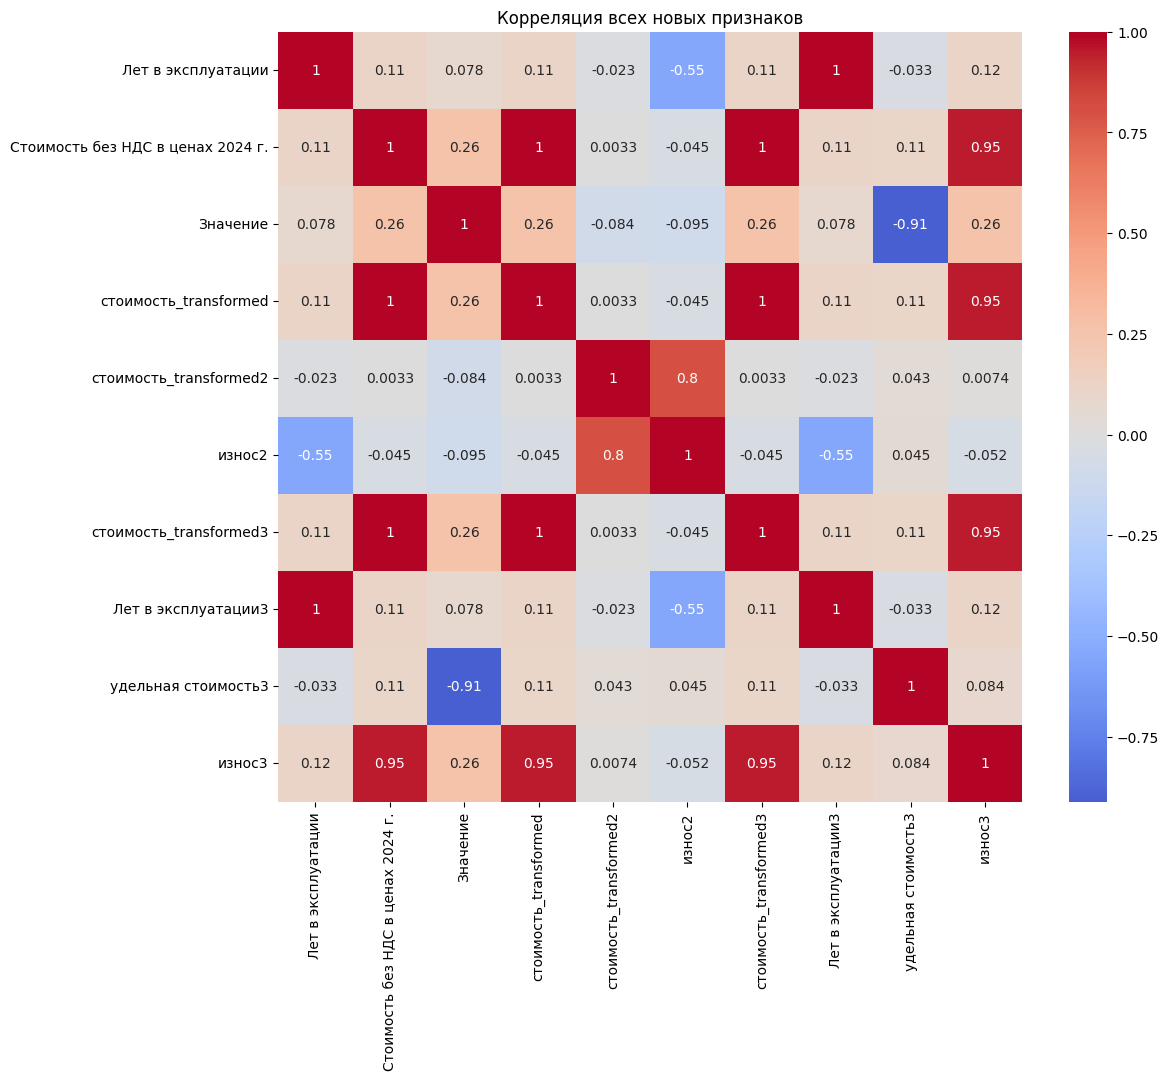

In [91]:
num_cols = df.select_dtypes(include=["int64", "float64"]).columns

corr_matrix = df[num_cols].corr(method='spearman')

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", annot=True, center=0)
plt.title("Корреляция всех новых признаков")
plt.show()

In [92]:
compute_vif(df)

,feature,VIF
6,стоимость_transformed3,4.177200
1,Стоимость без НДС в ценах 2024 г.,3.557708
4,стоимость_transformed2,3.425566
0,Лет в эксплуатации,2.896471
3,стоимость_transformed,2.698226
8,удельная стоимость3,2.341456
2,Значение,2.201209
7,Лет в эксплуатации3,1.799529
5,износ2,1.424415
9,износ3,1.169785


# Классификация

In [93]:
target_col = "Наименование"

counts = df[target_col].value_counts()
valid_classes = counts[counts > 1].index
df_filtered = df[df[target_col].isin(valid_classes)].copy()

print("Удалено классов с 1 объектом:", (counts == 1).sum())
print("Осталось классов:", df_filtered[target_col].nunique())

X = df_filtered.drop(columns=[target_col])
y = df_filtered[target_col]

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    stratify=y_encoded,
    random_state=123
)

print("Размеры выборок:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Удалено классов с 1 объектом: 67
Осталось классов: 312
Размеры выборок:
X_train: (10032, 16) y_train: (10032,)
X_test: (2509, 16) y_test: (2509,)


In [94]:
preprocessor_linear = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols)
])

preprocessor_boosting = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

cat_indices = [X.columns.get_loc(col) for col in cat_cols]

In [95]:
def ros(X, y, random_state=123):
    ros_sampler = RandomOverSampler(random_state=random_state)
    return ros_sampler.fit_resample(X, y)

def gaussian_noise_oversample(X, y, noise_level=0.05, random_state=123):
    np.random.seed(random_state)
    X_res, y_res = X.copy(), y.copy()
    classes, counts = np.unique(y, return_counts=True)
    max_count = counts.max()
    
    for cls, count in zip(classes, counts):
        X_cls = X[y == cls]
        n_to_add = max_count - count
        if n_to_add <= 0:
            continue
        mean = X_cls.mean(axis=0)
        std = X_cls.std(axis=0)
        X_new = np.random.normal(loc=mean, scale=std*noise_level, size=(n_to_add, X.shape[1]))
        y_new = np.array([cls]*n_to_add)
        X_res = np.vstack([X_res, X_new])
        y_res = np.concatenate([y_res, y_new])
    return X_res, y_res

def safe_smote(X, y, random_state=123):
    classes, counts = np.unique(y, return_counts=True)
    min_class_size = counts.min()
    k_opt = max(1, min(5, min_class_size-1))
    smote = SMOTE(random_state=random_state, k_neighbors=k_opt)
    return smote.fit_resample(X, y)

balancers = {
    "ros": ros,
    "gaussian_noise": gaussian_noise_oversample,
    "smote": safe_smote
}

In [96]:
def run_experiment(model, model_name, preprocessor, balancers_dict):
    results = []
    
    for bal_name, bal_func in balancers_dict.items():
        print(f"Запуск: {model_name} + {bal_name}")
        
        try:
            if preprocessor is not None:
                X_train_prep = preprocessor.fit_transform(X_train)
                X_test_prep  = preprocessor.transform(X_test)

                if hasattr(X_train_prep, "toarray"):
                    X_train_prep = X_train_prep.toarray()
                if hasattr(X_test_prep, "toarray"):
                    X_test_prep = X_test_prep.toarray()
            else:
                X_train_prep = X_train.copy()
                X_test_prep  = X_test.copy()

            y_train_local = y_train.copy()
            y_test_local  = y_test.copy()
            
            X_train_bal, y_train_bal = bal_func(X_train_prep, y_train_local)
            
            start_time = time.time()
            model.fit(X_train_bal, y_train_bal)
            elapsed_time = time.time() - start_time
            
            y_pred = model.predict(X_test_prep)
            acc = accuracy_score(y_test_local, y_pred)
            
            results.append({
                "model": model_name,
                "balancing": bal_name,
                "accuracy": acc,
                "train_time_sec": elapsed_time
            })
            
        except Exception as e:
            print(f"Ошибка в {model_name} + {bal_name}: {e}")
            continue
    
    if len(results) == 0:
        print("Все эксперименты вылетели. Нечего возвращать.")
        return pd.DataFrame()
    
    return pd.DataFrame(results).sort_values(by="accuracy", ascending=False)

In [97]:
class GaussianNoiseSampler(BaseEstimator):
    def __init__(self, noise_level=0.05, random_state=123):
        self.noise_level = noise_level
        self.random_state = random_state

    def fit_resample(self, X, y):
        np.random.seed(self.random_state)
        
        X_res, y_res = X.copy(), y.copy()
        classes, counts = np.unique(y, return_counts=True)
        max_count = counts.max()

        for cls, count in zip(classes, counts):
            X_cls = X[y == cls]
            n_to_add = max_count - count
            if n_to_add <= 0:
                continue

            mean = X_cls.mean(axis=0)
            std = X_cls.std(axis=0)

            X_new = np.random.normal(
                loc=mean,
                scale=std * self.noise_level,
                size=(n_to_add, X.shape[1])
            )
            y_new = np.array([cls] * n_to_add)

            X_res = np.vstack([X_res, X_new])
            y_res = np.concatenate([y_res, y_new])

        return X_res, y_res

In [98]:
sampler = GaussianNoiseSampler(noise_level=0.05, random_state=123)

X_train_prep = preprocessor_linear.fit_transform(X_train)

if hasattr(X_train_prep, "toarray"):
    X_train_prep = X_train_prep.toarray()

print("До oversampling:")
print("X:", X_train_prep.shape)
print("y:", y_train.shape)

X_res, y_res = sampler.fit_resample(X_train_prep, y_train)

print("\nПосле GaussianNoiseSampler:")
print("X:", X_res.shape)
print("y:", y_res.shape)

До oversampling:
X: (10032, 162)
y: (10032,)

После GaussianNoiseSampler:
X: (158496, 162)
y: (158496,)


## Логистическая регрессия

In [99]:
logreg_ovr_model = OneVsRestClassifier(
    LogisticRegression(class_weight='balanced', random_state=123, n_jobs=-1),
    n_jobs=-1
)

logreg_ovr_results = run_experiment(
    logreg_ovr_model,
    "logreg_ovr",
    preprocessor_linear,
    balancers
)

logreg_ovr_results

Запуск: logreg_ovr + ros


Запуск: logreg_ovr + gaussian_noise
Запуск: logreg_ovr + smote


,model,balancing,accuracy,train_time_sec
0,logreg_ovr,ros,0.409725,54.833591
2,logreg_ovr,smote,0.405739,49.297196
1,logreg_ovr,gaussian_noise,0.393384,34.924210


In [ ]:
logreg_model = LogisticRegression(class_weight='balanced', random_state=123, n_jobs=-1)

logreg_results = run_experiment(
    logreg_model,
    "logreg",
    preprocessor_linear,
    balancers
)

logreg_results

In [ ]:
pipe_logreg1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler()),
    ('clf', LogisticRegression(
        class_weight='balanced',
        max_iter=100,
        random_state=123
    ))
])

param_logreg1 = {
    'clf__solver': ['lbfgs', 'saga'],
    'clf__multi_class': ['auto', 'multinomial']
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)

grid = GridSearchCV(
    pipe_logreg1,
    param_grid=param_logreg1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid.fit(X_train, y_train)
elapsed_time = time.time() - start_time

In [ ]:
print("Лучшие параметры:", grid.best_params_)
print("Лучшая CV accuracy:", grid.best_score_)
print("Время (сек):", elapsed_time)

y_pred = grid.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)

print("Test accuracy:", test_acc)

In [ ]:
pipe_logreg2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler()),
    ('clf', LogisticRegression(
        solver='lbfgs',
        multi_class='auto',
        class_weight='balanced',
        random_state=123
    ))
])

param_logreg2 = {
    'clf__C': [5, 10, 25, 50],
    'clf__max_iter': [100, 250, 500],
    'clf__l1_ratio': [None, 0.5]
}

grid2 = GridSearchCV(
    pipe_logreg2,
    param_grid=param_logreg2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 36 candidates, totalling 72 fits


In [65]:
print("Лучшие параметры:", grid2.best_params_)
print("Лучшая CV accuracy:", grid2.best_score_)
print("Время:", elapsed_time)

y_pred = grid2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))

Лучшие параметры: {'clf__C': 50, 'clf__l1_ratio': None, 'clf__max_iter': 250}
Лучшая CV accuracy: 0.4918261562998405
Время: 815.393963098526
Test accuracy: 0.49740932642487046


## SVM

In [ ]:
svm_model = SVC(
        kernel='rbf',
        max_iter=100,
        class_weight='balanced',
        probability=False,
        random_state=123
    )

svm_results = run_experiment(
    svm_model,
    "svm",
    preprocessor_linear,
    balancers
)

svm_results

In [55]:
svm_ovr_model = OneVsRestClassifier(SVC(
        kernel='rbf',
        max_iter=100,
        class_weight='balanced',
        probability=False,
        random_state=123), n_jobs=-1
    )

svm_ovr_results = run_experiment(
    svm_ovr_model,
    "svm_ovr",
    preprocessor_linear,
    balancers
)

svm_ovr_results

Запуск: svm_ovr + ros


Запуск: svm_ovr + gaussian_noise
Запуск: svm_ovr + smote


,model,balancing,accuracy,train_time_sec
1,svm_ovr,gaussian_noise,0.376644,53.007730
2,svm_ovr,smote,0.261857,63.319550
0,svm_ovr,ros,0.219609,54.709326


In [ ]:
pipe_svm1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler()),  
    ('clf', SVC(
        class_weight='balanced',
        random_state=123,
        max_iter=100
    ))
])

param_svm_grid1 = {
    'clf__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'clf__gamma': ['scale', 'auto'],
    'clf__decision_function_shape': ['ovo', 'ovr']
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm1 = GridSearchCV(
    pipe_svm1,
    param_grid=param_svm_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

In [ ]:
print("Лучшие параметры:", grid_svm1.best_params_)
print("Лучшая CV accuracy:", grid_svm1.best_score_)
print("Время (сек):", elapsed_time)

test_acc = grid_svm1.score(X_test, y_test)
print("Test accuracy:", test_acc)

In [90]:
pipe_svm2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler()),  
    ('clf', SVC(
        kernel='linear',
        gamma='scale',
        decision_function_shape='ovo',
        class_weight='balanced',
        random_state=123
    ))
])

param_svm2 = {
    'clf__degree': [1, 2, 3],
    'clf__C': [5, 10, 15],       
    'clf__tol': [1e-2, 1e-3, 1e-4],          
    'clf__max_iter': [200, 500, 1000]
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm2 = GridSearchCV(
    pipe_svm2,
    param_grid=param_svm2,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 81 candidates, totalling 162 fits


In [91]:
print("Лучшие параметры:", grid_svm2.best_params_)
print("Лучшая CV accuracy:", grid_svm2.best_score_)
y_pred_test =grid_svm2.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)
print("Test accuracy:", test_acc)
print("Время обучения (сек):", elapsed_time)

Лучшие параметры: {'clf__C': 10, 'clf__degree': 1, 'clf__max_iter': 1000, 'clf__tol': 0.01}
Лучшая CV accuracy: 0.5414673046251994
Test accuracy: 0.5296931048226385
Время обучения (сек): 970.6038537025452


## KNN

In [ ]:
knn_model = KNeighborsClassifier(
        n_jobs=-1
    )

knn_results = run_experiment(
    knn_model,
    "knn_ovr",
    preprocessor_linear,
    balancers
)

knn_results

In [ ]:
pipe_knn1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler()),
    ('clf', KNeighborsClassifier())
])

param_knn_grid1 = {
    'clf__weights': ['uniform', 'distance'],
    'clf__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)

grid_knn1 = GridSearchCV(
    pipe_knn1,
    param_grid=param_knn_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

In [ ]:
print("Лучшие параметры:", grid_knn1.best_params_)
print("Лучшая CV accuracy:", grid_knn1.best_score_)

y_pred = grid_knn1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

In [ ]:
pipe_knn2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler()),
    ('clf', KNeighborsClassifier(
        weights='distance',
        algorithm='auto'
    ))
])

param_knn2 = [
    
    {
        'clf__n_neighbors': [3, 5, 10],
        'clf__metric': ['minkowski'],
        'clf__p': [1, 2],
        'clf__leaf_size': [1, 2, 3, 5, 10]
    },

    {
        'clf__n_neighbors': [3, 5, 10],
        'clf__metric': ['euclidean', 'manhattan', 'chebyshev'],
        'clf__leaf_size': [1, 2, 3, 5, 10]
    }
]

grid_knn2 = GridSearchCV(
    pipe_knn2,
    param_grid=param_knn2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 75 candidates, totalling 225 fits


In [97]:
print("Лучшие параметры:", grid_knn2.best_params_)
print("Лучшая CV accuracy:", grid_knn2.best_score_)

y_pred = grid_knn2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__leaf_size': 1, 'clf__metric': 'minkowski', 'clf__n_neighbors': 10, 'clf__p': 1}
Лучшая CV accuracy: 0.4995015948963317
Test accuracy: 0.5093662813870068
Время: 823.4874942302704


## Дерево решений

In [56]:
tree_model = DecisionTreeClassifier(
        class_weight='balanced',
        random_state=123
    )

tree_results = run_experiment(
    tree_model,
    "tree_ovr",
    preprocessor_tree,
    balancers
)

tree_results

Запуск: tree_ovr + ros
Запуск: tree_ovr + gaussian_noise
Запуск: tree_ovr + smote


,model,balancing,accuracy,train_time_sec
0,tree_ovr,ros,0.555998,3.131307
1,tree_ovr,gaussian_noise,0.551614,32.124571
2,tree_ovr,smote,0.550020,33.556097


In [53]:
pipe_tree1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', DecisionTreeClassifier(
        class_weight='balanced',
        random_state=123
    ))
])

param_tree_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__splitter': ['best', 'random'],
    'clf__max_features': [None, 'sqrt', 'log2']
}

grid_tree1 = GridSearchCV(
    pipe_tree1,
    param_grid=param_tree_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 18 candidates, totalling 54 fits


In [54]:
print("Лучшие параметры:", grid_tree1.best_params_)
print("Лучшая CV accuracy:", grid_tree1.best_score_)

y_pred = grid_tree1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'entropy', 'clf__max_features': None, 'clf__splitter': 'best'}
Лучшая CV accuracy: 0.5469497607655502
Test accuracy: 0.5603826225587883
Время: 3.5917413234710693


In [80]:
pipe_tree2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', DecisionTreeClassifier(
        criterion='entropy',
        max_features=None,
        splitter='best',
        class_weight='balanced',
        random_state=123
    ))
])

param_tree_grid2 = {
    'clf__max_depth': [None, 3, 5, 10, 20, 30],
    'clf__min_samples_split': [None, 1, 2, 5, 10],
    'clf__min_samples_leaf': [None, 1, 2, 5, 10, 20]
}

grid_tree2 = GridSearchCV(
    pipe_tree2,
    param_grid=param_tree_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 5 folds for each of 180 candidates, totalling 900 fits


In [81]:
print("Лучшие параметры:", grid_tree2.best_params_)
print("Лучшая CV accuracy:", grid_tree2.best_score_)

y_pred = grid_tree2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': 20, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2}
Лучшая CV accuracy: 0.5515335408820872
Test accuracy: 0.5639697090474293
Время: 37.364956855773926


## Случайный лес

In [ ]:
rf_model = RandomForestClassifier(
        class_weight='balanced',
        n_jobs=-1,
        random_state=123
    )

rf_results = run_experiment(
    rf_model,
    "rf_ovr",
    preprocessor_tree,
    balancers
)

rf_results

In [ ]:
pipe_rf1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', GaussianNoiseSampler()),
    ('clf', RandomForestClassifier(
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__max_features': ['sqrt', 'log2'],
    'clf__class_weight': [None, 'balanced', 'balanced_subsample']
}

grid_rf1 = GridSearchCV(
    pipe_rf1,
    param_grid=param_rf_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

In [ ]:
print("Лучшие параметры:", grid_rf1.best_params_)
print("Лучшая CV accuracy:", grid_rf1.best_score_)

y_pred = grid_rf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

In [94]:
pipe_rf2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', GaussianNoiseSampler()),
    ('clf', RandomForestClassifier(
        criterion='gini',
        max_features='sqrt',
        class_weight=None,
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid2 = {
    'clf__n_estimators': [300, 500, 1000],
    'clf__max_depth': [None, 5, 20],
    'clf__min_samples_split': [2, 5, 10],
    'clf__min_samples_leaf': [1, 4, 10]
}

grid_rf2 = GridSearchCV(
    pipe_rf2,
    param_grid=param_rf_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 81 candidates, totalling 162 fits


In [95]:
print("Лучшие параметры:", grid_rf2.best_params_)
print("Лучшая CV accuracy:", grid_rf2.best_score_)

y_pred = grid_rf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 5, 'clf__n_estimators': 1000}
Лучшая CV accuracy: 0.578847687400319
Test accuracy: 0.6129932243921882
Время: 9870.9009578228


## Вращающийся лес

In [64]:
rtf_model = RotationForestClassifier(
    n_estimators=100,
    n_jobs=-1,
    random_state=123
)

rtf_results = run_experiment(
    rtf_model,
    "rtf",
    preprocessor_tree,
    balancers
)

rtf_results

Запуск: rtf + ros
Запуск: rtf + gaussian_noise
Запуск: rtf + smote


,model,balancing,accuracy,train_time_sec
0,rtf,ros,0.609406,45.758899
1,rtf,gaussian_noise,0.607015,531.607074
2,rtf,smote,0.597449,588.666131


In [ ]:
pipe_rtf = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__min_group": [3, 5],
    "model__max_group": [5, 10],
    "model__remove_proportion": [0.3, 0.7]
}

grid_rtf = GridSearchCV(
    pipe_rtf,
    param_grid=param_rtf_grid,
    scoring="accuracy",
    cv=3,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 54 candidates, totalling 108 fits


In [42]:
print("Лучшие параметры:", grid_rtf.best_params_)
print("Лучшая CV accuracy:", grid_rtf.best_score_)

y_pred = grid_rtf.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_group': 5, 'model__min_group': 3, 'model__n_estimators': 100, 'model__remove_proportion': 0.3}
Лучшая CV accuracy: 0.5838317384370015
Test accuracy: 0.6062176165803109
Время: 1873.9888479709625


## GBoost

In [ ]:
gb_model = GradientBoostingClassifier(
    n_estimators=100,          
    n_iter_no_change=5,    
    tol=1e-3,                
    random_state=123
)

gb_results = run_experiment(
    gb_model,
    "gb",
    preprocessor_boosting,
    balancers
)

gb_results 

In [ ]:
pipe_gb1 = Pipeline([
    ('preprocessor', preprocessor_boosting),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', GradientBoostingClassifier(
        n_estimators=100,
        n_iter_no_change=5,
        tol=1e-3,
        random_state=123
    ))
])

param_gb_grid1 = {
    'clf__loss': ['log_loss', 'deviance', 'exponential'],
    'clf__criterion': ['friedman_mse', 'squared_error'],
    'clf__max_features': [None, 'sqrt', 'log2']
}

grid_gb1 = GridSearchCV(
    pipe_gb1,
    param_grid=param_gb_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_gb1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

In [ ]:
print("Лучшие параметры:", grid_gb1.best_params_)
print("Лучшая CV accuracy:", grid_gb1.best_score_)

y_pred = grid_gb1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

In [39]:
pipe_gb2 = Pipeline([
    ('preprocessor', preprocessor_boosting),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', GradientBoostingClassifier(
        loss='log_loss',
        criterion='squared_error',
        max_features=None,
        n_iter_no_change=3,
        tol=1e-2,
        random_state=123
    ))
])

param_gb_grid2 = {
    'clf__n_estimators': [100, 200, 300],
    'clf__learning_rate': [0.05, 0.1],
    'clf__max_depth': [3, 5],
    'clf__min_samples_leaf': [1, 5],
    'clf__min_samples_split': [2, 6]
}

grid_gb2 = GridSearchCV(
    pipe_gb2,
    param_grid=param_gb_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_gb2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 48 candidates, totalling 96 fits


In [40]:
print("Лучшие параметры:", grid_gb2.best_params_)
print("Лучшая CV accuracy:", grid_gb2.best_score_)

y_pred = grid_gb2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.05, 'clf__max_depth': 5, 'clf__min_samples_leaf': 5, 'clf__min_samples_split': 2, 'clf__n_estimators': 100}
Лучшая CV accuracy: 0.4902312599681021
Test accuracy: 0.4854523714627342
Время: 12039.3191781044


## AdaBoost

In [39]:
ada_model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=123),
        n_estimators=100,
        random_state=123
    )

ada_results = run_experiment(
    ada_model,
    "ada",
    preprocessor_boosting,
    balancers
)

ada_results

Запуск: ada + ros
Запуск: ada + gaussian_noise
Запуск: ada + smote


,model,balancing,accuracy,train_time_sec
1,ada,gaussian_noise,0.448784,1106.911340
0,ada,ros,0.437226,92.831101
2,ada,smote,0.391790,473.763071


In [43]:
pipe_ada1 = Pipeline([
    ('preprocessor', preprocessor_boosting),
    ('balancer', GaussianNoiseSampler()),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=5,
            class_weight='balanced',
            random_state=123
        ),
        n_estimators=100,
        random_state=123
    ))
])

param_ada_grid1 = {
    'clf__estimator__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__estimator__splitter': ['best', 'random'],
    'clf__estimator__max_features': [None, 'sqrt', 'log2']
}

grid_ada1 = GridSearchCV(
    pipe_ada1,
    param_grid=param_ada_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 18 candidates, totalling 54 fits


In [44]:
print("Лучшие параметры:", grid_ada1.best_params_)
print("Лучшая CV accuracy:", grid_ada1.best_score_)

y_pred = grid_ada1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__criterion': 'gini', 'clf__estimator__max_features': None, 'clf__estimator__splitter': 'best'}
Лучшая CV accuracy: 0.4499601275917065
Test accuracy: 0.44878437624551615
Время: 3016.168758869171


In [41]:
pipe_ada2 = Pipeline([
    ('preprocessor', preprocessor_boosting),
    ('balancer', GaussianNoiseSampler()),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            max_features=None,
            class_weight='balanced',
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid2 = {
    'clf__n_estimators': [100, 200, 300],
    'clf__learning_rate': [0.05, 0.1],
    'clf__estimator__max_depth': [3, 5],
    'clf__estimator__min_samples_split': [2, 5],
    'clf__estimator__min_samples_leaf': [1, 3]
}

grid_ada2 = GridSearchCV(
    pipe_ada2,
    param_grid=param_ada_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 48 candidates, totalling 96 fits


In [42]:
print("Лучшие параметры:", grid_ada2.best_params_)
print("Лучшая CV accuracy:", grid_ada2.best_score_)

y_pred = grid_ada2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__max_depth': 5, 'clf__estimator__min_samples_leaf': 1, 'clf__estimator__min_samples_split': 2, 'clf__learning_rate': 0.1, 'clf__n_estimators': 300}
Лучшая CV accuracy: 0.4491626794258373
Test accuracy: 0.46113989637305697
Время: 10714.496944189072


## CatBoost

In [ ]:
X_train_bal, y_train_bal = ros(X_train, y_train)

pipe_cb = Pipeline([
    ("model", CatBoostClassifier(
        loss_function='MultiClass',
        early_stopping_rounds=3,
        thread_count=-1,
        random_state=123,
        verbose=2
    ))
])

param_cb = {
    "model__iterations": [100, 200],
    "model__depth": [5, 10],
    "model__learning_rate": [0.05, 0.1],
    "model__l2_leaf_reg": [5, 7]
}

grid_cb = GridSearchCV(
    pipe_cb,
    param_grid=param_cb,
    scoring="accuracy",
    cv=2,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_cb.fit(X_train_bal, y_train_bal, model__cat_features=cat_indices)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 16 candidates, totalling 32 fits


0:	learn: 5.1738960	total: 21m 53s	remaining: 1d 12h 6m 49s
0:	learn: 5.4781131	total: 22m 7s	remaining: 1d 12h 29m 33s
0:	learn: 5.1508212	total: 23m 12s	remaining: 1d 14h 17m 29s
0:	learn: 5.4890084	total: 23m 25s	remaining: 1d 14h 39m 18s
0:	learn: 5.4377051	total: 23m 35s	remaining: 1d 14h 56m 18s


In [ ]:
print("Лучшие параметры:", grid_cb.best_params_)
y_pred = grid_cb.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print("Accuracy:", acc)
print("Время:", elapsed_time)

## Keras

In [ ]:
def run_experiment_keras(model, balancers_dict, X_train, y_train, X_test, y_test, preprocessor=None, epochs=50, batch_size=32):
    results = []

    for bal_name, bal_func in balancers_dict.items():
        print(f"Запуск Keras + {bal_name}")
        try:
            if preprocessor is not None:
                X_train_proc = preprocessor.fit_transform(X_train)
                X_test_proc  = preprocessor.transform(X_test)
                if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
                if hasattr(X_test_proc, "toarray"): X_test_proc = X_test_proc.toarray()
            else:
                X_train_proc = X_train.copy()
                X_test_proc  = X_test.copy()

            X_train_bal, y_train_bal = bal_func(X_train_proc, y_train)

            classes = np.unique(y_train_bal)
            class_weights = compute_class_weight('balanced', classes=classes, y=y_train_bal)
            class_weights_dict = dict(zip(classes, class_weights))

            input_dim = X_train_bal.shape[1]
            n_classes = len(classes)
            model_copy = Sequential([
                Dense(64, activation='relu', input_shape=(input_dim,)),
                Dropout(0.3),
                Dense(32, activation='relu'),
                Dense(n_classes, activation='softmax')
            ])
            model_copy.compile(
                optimizer='adam',
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy']
            )

            start_time = time.time()
            history = model_copy.fit(
                X_train_bal, y_train_bal,
                epochs=epochs,
                batch_size=batch_size,
                validation_split=0.2,
                class_weight=class_weights_dict,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=1
            )
            elapsed_time = time.time() - start_time

            y_pred_probs = model_copy.predict(X_test_proc)
            y_pred = np.argmax(y_pred_probs, axis=1) if y_pred_probs.shape[1] > 1 else (y_pred_probs > 0.5).astype(int).flatten()
            acc = accuracy_score(y_test, y_pred)

            results.append({
                "balancing": bal_name,
                "accuracy": acc,
                "train_time_sec": elapsed_time
            })
            print(f"{bal_name}: Accuracy={acc:.4f}, Time={elapsed_time:.1f}s")

        except Exception as e:
            print(f"Ошибка при {bal_name}: {e}")
            continue

    if len(results) == 0:
        print("Все эксперименты вылетели. Нечего возвращать.")
        return pd.DataFrame()

    return pd.DataFrame(results).sort_values(by="accuracy", ascending=False)

In [44]:
n_classes = len(np.unique(y_encoded))

preprocessor_nn = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

In [45]:
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(n_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

keras_results = run_experiment_keras(
    model=model,
    balancers_dict=balancers,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    preprocessor=preprocessor_nn,
    epochs=50,
    batch_size=32
)

Запуск Keras + ros
Epoch 1/50
3963/3963 ━━━━━━━━━━━━━━━━━━━━ 3s 636us/step - accuracy: 0.4277 - loss: 2.2800 - val_accuracy: 0.0589 - val_loss: 9.8323
Epoch 2/50
3963/3963 ━━━━━━━━━━━━━━━━━━━━ 2s 603us/step - accuracy: 0.5824 - loss: 1.4595 - val_accuracy: 0.0860 - val_loss: 6.8769
... (вывод сокращён: 145 строк) ...
3963/3963 ━━━━━━━━━━━━━━━━━━━━ 2s 617us/step - accuracy: 0.7842 - loss: 0.7187 - val_accuracy: 0.3572 - val_loss: 2.5193
Epoch 15/50
3963/3963 ━━━━━━━━━━━━━━━━━━━━ 3s 629us/step - accuracy: 0.7871 - loss: 0.7070 - val_accuracy: 0.3093 - val_loss: 2.6788
Epoch 16/50
3963/3963 ━━━━━━━━━━━━━━━━━━━━ 2s 614us/step - accuracy: 0.7894 - loss: 0.6954 - val_accuracy: 0.3527 - val_loss: 2.5613
Epoch 17/50
3963/3963 ━━━━━━━━━━━━━━━━━━━━ 2s 622us/step - accuracy: 0.7930 - loss: 0.6877 - val_accuracy: 0.3428 - val_loss: 2.4027
Epoch 18/50
3963/3963 ━━━━━━━━━━━━━━━━━━━━ 2s 623us/step - accuracy: 0.7954 - loss: 0.6759 - val_accuracy: 0.3722 - val_loss: 2.4680
Epoch 19/50
3963/3963 ━━━━━━

In [46]:
keras_results

,balancing,accuracy,train_time_sec
1,gaussian_noise,0.512953,55.917908
2,smote,0.493025,55.140782
0,ros,0.481467,89.892439


In [51]:
def grid_search_keras_strings(X_train, y_train, X_test, y_test, preprocessor, balancer, string_params, epochs=50, batch_size=32):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc, "toarray"): X_test_proc = X_test_proc.toarray()

    X_train_bal, y_train_bal = balancer.fit_resample(X_train_proc, y_train)

    classes = np.unique(y_train_bal)
    class_weights = compute_class_weight('balanced', classes=classes, y=y_train_bal)
    class_weights_dict = dict(zip(classes, class_weights))
    n_classes = len(classes)
    input_dim = X_train_bal.shape[1]

    results = []
    keys, values = zip(*string_params.items())
    for v in product(*values):
        params = dict(zip(keys, v))
        model_copy = Sequential([
            Dense(64, activation=params.get('activation','relu'), input_shape=(input_dim,)),
            Dropout(0.3),
            Dense(32, activation=params.get('activation','relu')),
            Dense(n_classes, activation='softmax')
        ])
        if params.get('optimizer','adam') == 'adam':
            opt = Adam(learning_rate=0.01)
        elif params.get('optimizer') == 'sgd':
            opt = SGD(learning_rate=0.01)
        else:
            opt = RMSprop(learning_rate=0.01)
        model_copy.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])

        model_copy.fit(
            X_train_bal, y_train_bal,
            epochs=epochs,
            batch_size=batch_size,
            validation_split=0.2,
            class_weight=class_weights_dict,
            callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
            verbose=2
        )

        y_pred_probs = model_copy.predict(X_test_proc)
        y_pred = np.argmax(y_pred_probs, axis=1)
        acc = accuracy_score(y_test, y_pred)
        results.append({**params, "accuracy": acc})
    
    df_results = pd.DataFrame(results).sort_values(by="accuracy", ascending=False)
    return df_results

In [52]:
def grid_search_keras_numeric(X_train, y_train, X_test, y_test, preprocessor, balancer, best_string_params, numeric_params):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc, "toarray"): X_test_proc = X_test_proc.toarray()

    X_train_bal, y_train_bal = balancer.fit_resample(X_train_proc, y_train)

    classes = np.unique(y_train_bal)
    class_weights = compute_class_weight('balanced', classes=classes, y=y_train_bal)
    class_weights_dict = dict(zip(classes, class_weights))
    n_classes = len(classes)
    input_dim = X_train_bal.shape[1]

    results = []
    keys, values = zip(*numeric_params.items())
    from itertools import product
    for v in product(*values):
        params = dict(zip(keys, v))
        activation = best_string_params['activation']
        optimizer_name = best_string_params['optimizer']

        model_copy = Sequential([
            Dense(params.get('n_size',64), activation=activation, input_shape=(input_dim,)),
            Dropout(0.3),
            Dense(params.get('n_size',64)//2, activation=activation),
            Dense(n_classes, activation='softmax')
        ])
        lr = params.get('learning_rate',0.01)
        if optimizer_name == 'adam':
            opt = Adam(learning_rate=lr)
        elif optimizer_name == 'sgd':
            opt = SGD(learning_rate=lr)
        else:
            opt = RMSprop(learning_rate=lr)
        model_copy.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])

        start_time = time.time()
        model_copy.fit(
            X_train_bal, y_train_bal,
            epochs=params.get('epochs',50),
            batch_size=params.get('batch_size',32),
            validation_split=0.2,
            class_weight=class_weights_dict,
            callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
            verbose=2
        )
        elapsed_time = time.time() - start_time

        y_pred_probs = model_copy.predict(X_test_proc)
        y_pred = np.argmax(y_pred_probs, axis=1)
        acc = accuracy_score(y_test, y_pred)
        results.append({**params, "accuracy": acc, "train_time_sec": elapsed_time})

    df_results = pd.DataFrame(results).sort_values(by="accuracy", ascending=False)
    return df_results

In [53]:
df_strings = grid_search_keras_strings(
    X_train, y_train, X_test, y_test,
    preprocessor=preprocessor_nn,
    balancer=GaussianNoiseSampler(),
    string_params={
        "activation": ["relu","tanh","sigmoid"],
        "optimizer": ["adam","sgd","rmsprop"]
    },
    epochs=50,
    batch_size=32
)
best_string_params = df_strings.iloc[0].to_dict()

Epoch 1/50
3963/3963 - 3s - 853us/step - accuracy: 0.8479 - loss: 0.7369 - val_accuracy: 0.1639 - val_loss: 5.2549
Epoch 2/50
3963/3963 - 2s - 617us/step - accuracy: 0.9091 - loss: 0.4321 - val_accuracy: 0.1744 - val_loss: 4.4673
Epoch 3/50
... (вывод сокращён: 193 строк) ...
Epoch 11/50
3963/3963 - 2s - 561us/step - accuracy: 0.9407 - loss: 0.3391 - val_accuracy: 0.0811 - val_loss: 6.9388
Epoch 12/50
3963/3963 - 2s - 569us/step - accuracy: 0.9411 - loss: 0.3378 - val_accuracy: 0.0948 - val_loss: 7.0901
Epoch 13/50
3963/3963 - 2s - 560us/step - accuracy: 0.9417 - loss: 0.3394 - val_accuracy: 0.1161 - val_loss: 6.8102
Epoch 14/50
3963/3963 - 2s - 566us/step - accuracy: 0.9414 - loss: 0.3390 - val_accuracy: 0.1094 - val_loss: 6.6107
Epoch 15/50
3963/3963 - 2s - 572us/step - accuracy: 0.9422 - loss: 0.3371 - val_accuracy: 0.0961 - val_loss: 7.1698
Epoch 16/50
3963/3963 - 2s - 565us/step - accuracy: 0.9418 - loss: 0.3374 - val_accuracy: 0.1218 - val_loss: 7.1090
Epoch 17/50
3963/3963 - 2s 

In [55]:
df_strings

,activation,optimizer,accuracy
6,sigmoid,adam,0.478677
3,tanh,adam,0.457951
8,sigmoid,rmsprop,0.438023
0,relu,adam,0.426465
2,relu,rmsprop,0.420486
5,tanh,rmsprop,0.396572
4,tanh,sgd,0.007971
1,relu,sgd,0.003986
7,sigmoid,sgd,0.003986


In [54]:
best_string_params

{'activation': 'sigmoid', 'optimizer': 'adam', 'accuracy': 0.47867676365085693}

In [56]:
df_numeric = grid_search_keras_numeric(
    X_train, y_train, X_test, y_test,
    preprocessor=preprocessor_nn,
    balancer=GaussianNoiseSampler(),
    best_string_params=best_string_params,
    numeric_params={
        "n_size":[32, 64, 128],
        "learning_rate":[0.01, 0.05, 0.1],
        "batch_size":[32, 64, 128],
        "epochs":[100, 250, 500]
    }
)

Epoch 1/100
3963/3963 - 3s - 719us/step - accuracy: 0.5243 - loss: 2.0224 - val_accuracy: 0.0311 - val_loss: 7.1754
Epoch 2/100
3963/3963 - 2s - 552us/step - accuracy: 0.7916 - loss: 0.9101 - val_accuracy: 0.0494 - val_loss: 5.6370
Epoch 3/100
... (вывод сокращён: 3009 строк) ...
Epoch 6/500
991/991 - 2s - 2ms/step - accuracy: 0.0158 - loss: 4.4032 - val_accuracy: 0.0000e+00 - val_loss: 9.3669
Epoch 7/500
991/991 - 2s - 2ms/step - accuracy: 0.0162 - loss: 4.3942 - val_accuracy: 0.0000e+00 - val_loss: 9.3271
Epoch 8/500
991/991 - 2s - 2ms/step - accuracy: 0.0157 - loss: 4.3958 - val_accuracy: 0.0000e+00 - val_loss: 9.1475
Epoch 9/500
991/991 - 2s - 2ms/step - accuracy: 0.0156 - loss: 4.3957 - val_accuracy: 0.0000e+00 - val_loss: 9.0141
Epoch 10/500
991/991 - 2s - 2ms/step - accuracy: 0.0160 - loss: 4.4013 - val_accuracy: 0.0000e+00 - val_loss: 9.1361
Epoch 11/500
991/991 - 2s - 2ms/step - accuracy: 0.0159 - loss: 4.3876 - val_accuracy: 0.0000e+00 - val_loss: 9.3634
Epoch 12/500
991/991 

In [57]:
df_numeric

,n_size,learning_rate,batch_size,epochs,accuracy,train_time_sec
60,128,0.01,128,100,0.526903,41.578340
62,128,0.01,128,500,0.521722,21.927360
35,64,0.01,128,500,0.518533,47.360343
59,128,0.01,64,500,0.515345,32.518761
33,64,0.01,128,100,0.512156,39.792854
...,...,...,...,...,...,...
76,128,0.10,64,250,0.001993,15.763524
77,128,0.10,64,500,0.001993,22.223348
79,128,0.10,128,250,0.000797,22.535969
50,64,0.10,64,500,0.000399,10.970670


# Fedot

Следующим шагом я подготовил данные для многоклассовой классификации. В исходном датасете часть классов встречалась всего один раз, что делает их непригодными для обучения. Я отфильтровал такие наблюдения, оставив только классы с количеством объектов больше одного. В результате осталось 312 классов и 12 541 запись

In [ ]:
X = df[num_cols + cat_cols].copy()
y = df["Наименование"].copy()

counts = y.value_counts()
valid_classes = counts[counts > 1].index

mask = y.isin(valid_classes)

X = X[mask]
y = y[mask]

print("Осталось классов:", y.nunique())
print("Размер:", len(y))

Далее данные были разделены на обучающую и тестовую выборки со стратификацией по целевой переменной. Это важно в условиях большого числа классов, так как позволяет сохранить их распределение и избежать потери редких классов в одной из выборок

Потом я провел балансировку классов с помощью SMOTENC. Этот метод расширяет выборку за счёт генерации синтетических объектов для редких классов - числовые признаки интерполируются, а категориальные выбираются из ближайших соседей. В результате каждый класс в обучающей выборке был увеличен до 508 наблюдений, а общий размер вырос до 158 496

После этого категориальные признаки были закодированы с помощью One-Hot Encoding и объединены с числовыми

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=123,
    stratify=y
)

cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(exclude='object').columns.tolist()

cat_features_idx = [X.columns.get_loc(col) for col in cat_cols]


smote = SMOTENC(
    categorical_features=cat_features_idx,
    k_neighbors=1,
    random_state=123
)

X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("После SMOTE:")
print(pd.Series(y_train_res).value_counts().head())

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

X_train_cat = ohe.fit_transform(X_train_res[cat_cols])
X_train_cat = pd.DataFrame(
    X_train_cat,
    columns=ohe.get_feature_names_out(cat_cols)
)

X_test_cat = ohe.transform(X_test[cat_cols])
X_test_cat = pd.DataFrame(
    X_test_cat,
    columns=ohe.get_feature_names_out(cat_cols)
)

X_train_num = X_train_res[num_cols].reset_index(drop=True)
X_test_num = X_test[num_cols].reset_index(drop=True)

X_train_cat = X_train_cat.reset_index(drop=True)
X_test_cat = X_test_cat.reset_index(drop=True)

X_train_final = pd.concat([X_train_num, X_train_cat], axis=1)
X_test_final = pd.concat([X_test_num, X_test_cat], axis=1)

print("Train shape:", X_train_final.shape)
print("y_train shape:", y_train_res.shape)

assert X_train_final.shape[0] == y_train_res.shape[0]

Для обучения использовалась библиотека Fedot. Это AutoML-инструмент, который автоматически подбирает и строит pipeline. В данном случае из-за ограничения по времени использовался упрощённый режим, и итоговый pipeline состоял из масштабирования признаков и модели Random Forest. То есть Fedot фактически выбрал базовую, но устойчивую комбинацию без глубокого перебора гиперпараметров. Без параметра preset='fast_train' обучение заняло бы более двух часов. Fedot здесь используется как точка отсчёта (baseline), поэтому глубокая настройка AutoML не проводилась: она требует значительно больших вычислительных ресурсов 

In [ ]:
model = Fedot(
    problem='classification',
    timeout=1,      
    n_jobs=-1,
    preset='fast_train',
    seed=123,
    safe_mode=True
)

pipeline = model.fit(features=X_train_final, target=y_train_res)

In [ ]:
pipeline.print_structure()

In [ ]:
pipeline.show()

Accuracy составила 0.55, что является приемлемым результатом с учетом большого числа классов. При этом macro F1-score равен 0.38, что говорит о слабом качестве на редких классах, несмотря на балансировку, тогда как weighted F1-score (0.56) показывает хорошее качество на более частых классах

In [ ]:
y_pred = model.predict(X_test_final)
print(classification_report(y_test, y_pred))

In [ ]:
y_pred = model.predict(X_test_final)

acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}")

f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')
print(f"F1-score (macro): {f1_macro:.4f}")
print(f"F1-score (weighted): {f1_weighted:.4f}")

lb = LabelBinarizer()
lb.fit(np.concatenate([y_train_res, y_test]))
y_test_bin = lb.transform(y_test)
y_score_bin = lb.transform(y_pred)

roc_auc = roc_auc_score(y_test_bin, y_score_bin, average='macro', multi_class='ovr')
print(f"ROC-AUC (macro, OVR): {roc_auc:.4f}")

Задача остаётся сложной из-за большого числа классов, поэтому для дальнейшего улучшения качества имеет смысл увеличить время обучения и более глубоко настраивать модель